# How prompt bans move an LLM's path-search choices: a runnable demo

This notebook is a small, CPU-only walk-through of the artifact **"How prompt bans move an LLM's path-search choices"**, a behavioural and activation-space screen of **Qwen3-8B** (bf16, thinking off, temperature 1.0).

**The question.** Asked to *"write a path-search program"*, does the model always write BFS? If the prompt bans BFS, where does it go instead? Can the geometry of the model's hidden state at the end of the prompt predict that?

**What the artifact does** (`method.py` runs these stages in order):
1. It builds two coding tasks with hidden test suites: **T1** grid path (catalogue `bfs, dfs, bidir_bfs, iddfs, astar, dijkstra_unit`) and **T2** weighted shortest path.
2. It samples programs from Qwen3-8B under *baseline*, *forced* ("Implement X"), *name-masked* (X described, not named), *mention*, *ban* ("Do not use X") and *activation-removal* conditions.
3. It labels the algorithm of every program with a **runtime tracer plus AST rules** (a blind LLM judge is used only when the two disagree) and runs each program on the hidden tests.
4. It caches the read-position state **h_R** (the residual stream at the last prompt token, layers 8–28). From it, it builds a **geodesic manifold** of the forced-mode states at layer l*. It then **hash-commits forecasts** of where each ban will send the model: geodesic proximity, the model's own "most standard alternative" ranking, baseline frequency, and a probe decoder.
5. It runs the bans and scores the forecasts.

**Full-run headline (T1).**
- The baseline collapses: 200/200 programs are BFS.
- The model obeys `ban:bfs` only 18% of the time: 62 BFS, 29 DFS and 9 unit-Dijkstra programs out of 100.
- The displaced mass lands only on BFS's **geodesic neighbours** on the manifold: DFS (distance 41) and unit-Dijkstra (58). It never reaches the far modes: A* (71), IDDFS (82) and bidirectional BFS (95).
- Removing the BFS direction from the activations moved 0 of 50 samples.

**What runs here.** Everything that needs the 16 GB model on a GPU is *replayed* from `mini_demo_data.json`. That file holds 96 stored T1 programs and the stored layer-27 states of 340 prompts. Every CPU stage runs live with the **original code**:
- hidden-test construction and the sandboxed test harness;
- the labeller and its unit tests;
- prompt construction and the Phase-A summary;
- the layer-27 manifold, the forecasts and the forecast contest.

T2 is left out so the demo stays on one dataset.

| `method.py` stage | full run | in this notebook |
|---|---|---|
| `tasks`, `labtests` | CPU | **live** (T1) |
| `prompts`, `succession` | CPU + Qwen3 tokenizer | **live**, prompt texts only (token ids need the tokenizer) |
| `phase_a`, `phase_c`, `phase_d`, `*_ext` | GPU sampling (about 2.2 h on one NVIDIA L4) | replayed: stored programs |
| `label_a` | CPU + OpenRouter judge | **live** on the stored programs (judge off by default) |
| `phase_b` | GPU (h_R) + CPU | h_R replayed; manifold, centroids and forecasts **live** |
| `analysis` | CPU | **live**: summaries, manifold figures, contest. Not run: the C3 decomposition needs the full 4096-d per-layer caches, and C2 removal needs the GPU |

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru: NOT on Colab, always install (every script of the artifact logs with loguru)
_pip('loguru==0.7.3')

# numpy, scipy, scikit-learn, matplotlib: pre-installed on Colab, install locally only (at Colab's versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'scikit-learn==1.6.1', 'matplotlib==3.10.0')
# (the optional LLM judge, USE_JUDGE below, also needs `openai`, which Colab pre-installs)

In [2]:
from __future__ import annotations

# ---- original imports (method.py, common.py, prompts/, tasks/, labeller/, gen/, hf/phase_b.py, analysis/)
import argparse
import ast
import asyncio
import hashlib
import heapq
import io
import itertools
import json
import math
import os
import random
import re
import shutil
import subprocess
import sys
import tempfile
import threading
import time
import tokenize
from collections import Counter, deque
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from typing import Any, Iterable

import numpy as np
from scipy.sparse import coo_matrix, csr_matrix
from scipy.sparse.csgraph import connected_components, minimum_spanning_tree, shortest_path
from scipy.spatial.distance import cdist

# ---- notebook additions (replaying stored samples, inline figures)
from collections import defaultdict

import matplotlib.pyplot as plt
from IPython.display import Image, display

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-1/experiment-2/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(data["metadata"]["description"])
print(f"programs: {len(data['datasets'][0]['examples'])} | read-position states: {len(data['hR_states']['index'])} prompts x "
      f"{data['hR_states']['dims']} coordinates (layer {data['hR_states']['layer']}) | "
      f"elicitation rankings: {len(data['elicitation_rankings'])}")
print("programs per condition:", data["metadata"]["selection"]["per_condition"])

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Curated T1 (grid path) subset of the path-search ban screen on Qwen3-8B (bf16, thinking off, T=1.0): labelled programs, read-position states at l*, committed forecasts.
programs: 96 | read-position states: 340 prompts x 179 coordinates (layer 27) | elicitation rankings: 120
programs per condition: {'baseline': 10, 'forced:bfs': 2, 'forced:dfs': 2, 'forced:bidir_bfs': 2, 'forced:iddfs': 2, 'forced:astar': 2, 'forced:dijkstra_unit': 2, 'masked:bfs': 1, 'masked:dfs': 1, 'masked:bidir_bfs': 1, 'masked:iddfs': 1, 'masked:astar': 1, 'masked:dijkstra_unit': 1, 'mention:bfs': 10, 'ban:bfs': 30, 'ban:bfs+dfs': 10, 'ban:bfs+dijkstra_unit': 10, 'removal:hooked_alpha0': 2, 'removal:dX_a2.0': 2, 'removal:full_dX_a4.0': 2, 'removal:full_r1_a4.0': 2}


## Configuration

All tunable parameters are set here. The values below are the demo scale, and the comments give the original values. The full run labelled 2310 programs from both tasks. It timed every catalogue reference 3 times and used 6 sandbox workers, 4 MDS restarts, 20 TwoNN nulls and 1000 bootstrap resamples.

- `MAX_PER_CONDITION` caps how many stored programs per condition are replayed and re-labelled. 30 takes all 96 programs in the demo file; the full run had up to 200 per condition.
- `USE_JUDGE = True` turns on the blind OpenRouter judge for the programs where runtime and AST disagree. It needs `OPENROUTER_BASE_URL` and `OPENROUTER_API_KEY`. With the judge off, the original fallback keeps the runtime (else AST, else `other`) label and marks it `runtime_only_unadjudicated`.

In [5]:
TASKS_RUN = ["t1"]        # tasks to run (original: ["t1", "t2"]; the demo data holds T1 only)
MAX_PER_CONDITION = 1     # stored programs replayed per condition (max 30 in the demo file -> all 96; full run: up to 200)
REF_REPS = 1              # `tasks` stage: timing runs per catalogue reference (original: 3)
LABEL_WORKERS = 2         # parallel sandbox workers for tests + traces (original: 6)
USE_JUDGE = False         # blind OpenRouter LLM judge on runtime/AST disagreements (original: True; needs API keys)
KNN_K = 10                # neighbours in the kNN graph of the manifold (original: 10)
MDS_N_INIT = 1            # SMACOF restarts of the geodesic MDS map (original: 4)
N_TWONN_NULLS = 2         # column-shuffled nulls for the TwoNN intrinsic dimension (original: 20)
N_BOOT_GEO = 10           # bootstrap resamples for forecast stability (original: 1000)

## 1. Shared definitions (`common.py`)

This cell holds the task specs, the algorithm catalogue, the display names and the prompt templates of every condition. It also holds small helpers:
- the Wilson interval;
- the Hill number of order 1, `exp(entropy)` of the label counts, used as the diversity measure;
- the Jensen–Shannon divergence.

It is copied from `common.py`. Only the working folder (`ROOT`) and the task list change.

In [6]:
# ==== common.py ====
# Shared constants, task specs, catalogue, prompt templates and helpers for the path-search ban screen.
# Every phase script imports this module, so condition names, display names and the shared row schema stay
# identical across phases (and across sibling screens that follow the same SHARED SCREEN PROTOCOL).
ROOT = Path("pathsearch_demo").resolve()  # notebook working folder (original: the artifact folder)
ROOT.mkdir(exist_ok=True)

# (The original also points the vLLM / Triton / inductor / flashinfer compiler caches into ROOT; no GPU stage runs here.)
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

MODEL_ID = "Qwen/Qwen3-8B"
MODEL_TAG = "Qwen3-8B-bf16"
DECODING_GEN = "T=1.0,top_p=1.0,top_k=off,min_p=0,max_tokens=1024,thinking=off,stop=closing_fence"
DECODING_HOOK = "T=1.0,top_p=1.0,top_k=off,max_new_tokens=768,thinking=off,hooked_hf,stop=closing_fence"

TASKS = TASKS_RUN  # original: ["t1", "t2"]
TASK_DATASET = {"t1": "t1_grid_path", "t2": "t2_weighted_sp"}
CACHE_LAYERS = list(range(8, 29))  # l = output of decoder block l = hidden_states[l + 1]
N_LAYERS_MODEL = 36

SPEC = {
    "t1": (
        "Write a Python function solve(grid, start, goal). grid is a list of equal-length strings over . (free) "
        "and # (wall), at most 30 rows and 30 columns; start and goal are (row, col) tuples of free cells. A move "
        "goes to one of the 4 orthogonal neighbours inside the grid. Return any valid path from start to goal as a "
        "list of (row, col) tuples including both endpoints, or [] if the goal is unreachable. Return only one "
        "```python code block containing the function and its imports."
    ),
    "t2": (
        "Write a Python function solve(n, edges, s, t). Nodes are 0..n-1 with n <= 100; edges is a list of directed "
        "(u, v, w) triples with integer weights 0 <= w <= 100, at most 1000 edges; cycles, self-loops and parallel "
        "edges may occur. Return the length of the shortest path from s to t, or -1 if t is unreachable. Return only "
        "one ```python code block containing the function and its imports."
    ),
}

CATALOGUE: dict[str, list[str]] = {
    "t1": ["bfs", "dfs", "bidir_bfs", "iddfs", "astar", "dijkstra_unit"],
    "t2": ["dijkstra", "bellman_ford_spfa", "bidir_dijkstra", "floyd_warshall", "dial"],
}

DISPLAY: dict[str, dict[str, str]] = {
    "t1": {
        "bfs": "breadth-first search (BFS)",
        "dfs": "depth-first search (DFS)",
        "bidir_bfs": "bidirectional BFS",
        "iddfs": "iterative-deepening DFS (IDDFS)",
        "astar": "A* search with a Manhattan-distance heuristic",
        "dijkstra_unit": "Dijkstra's algorithm",
    },
    "t2": {
        "dijkstra": "Dijkstra's algorithm",
        "bellman_ford_spfa": "Bellman-Ford (or SPFA)",
        "bidir_dijkstra": "bidirectional Dijkstra",
        "floyd_warshall": "Floyd-Warshall",
        "dial": "Dial's bucket-queue algorithm",
    },
}

ONE_LINE_DEF: dict[str, dict[str, str]] = {
    "t1": {
        "bfs": "breadth-first search: FIFO queue, level-by-level expansion from the start only",
        "dfs": "depth-first search: LIFO stack or recursion following one route deep and backtracking (no growing depth limit)",
        "bidir_bfs": "bidirectional BFS: two FIFO frontiers, one from the start and one from the goal, until they meet",
        "iddfs": "iterative-deepening DFS: depth-limited DFS restarted with limits 0,1,2,... until the goal is found",
        "astar": "A* (or greedy best-first): priority queue ordered by cost-so-far plus (or only) Manhattan distance to the goal",
        "dijkstra_unit": "Dijkstra with unit weights: priority queue (heap) ordered by step count only, no heuristic",
    },
    "t2": {
        "dijkstra": "Dijkstra: one binary heap (or repeated minimum selection) of tentative distances from the source",
        "bellman_ford_spfa": "Bellman-Ford (repeated sweeps over all edges) or SPFA (FIFO queue of improved nodes, no heap)",
        "bidir_dijkstra": "bidirectional Dijkstra: forward search from s and backward search from t on reversed edges",
        "floyd_warshall": "Floyd-Warshall: all-pairs n x n distance matrix with a triple loop over intermediate nodes",
        "dial": "Dial's algorithm: array of buckets indexed by integer distance scanned in increasing order, no heap",
    },
}

DESCRIPTIONS: dict[str, dict[str, list[str]]] = {
    "t1": {
        "bfs": [
            "explore cells in order of their step distance from the start, level by level, with a first-in-first-out queue",
            "expand the search outward one ring of equal step count at a time, always processing the earliest-discovered cell next",
            "keep a first-in-first-out frontier of discovered cells and record each cell's predecessor the first time it is reached",
        ],
        "dfs": [
            "follow one route as deep as possible and backtrack with a last-in-first-out stack or recursion",
            "keep extending the current route to an unvisited neighbour and step back only when the route gets stuck",
            "always continue from the most recently discovered cell, retreating to an earlier branch point at dead ends",
        ],
        "bidir_bfs": [
            "grow two level-by-level frontiers, one from the start and one from the goal, until they meet",
            "search outward from both endpoints at the same time, one ring of cells per round, and join the two halves where they touch",
            "alternate expanding a first-in-first-out frontier around the start and another around the goal, stopping when a cell is reached from both sides",
        ],
        "iddfs": [
            "repeat a depth-limited deep-first search with limits 0, 1, 2, ... until the goal is found",
            "run a deep-first search that may not exceed a maximum route length, and restart it with a larger maximum each time it fails",
            "combine deep-first exploration with a step budget that grows by one after every unsuccessful complete pass",
        ],
        "astar": [
            "always expand the cell with the smallest steps-so-far plus Manhattan distance to the goal",
            "rank frontier cells by the route length so far plus the row and column distance remaining to the goal, and expand the best-ranked one",
            "use a priority queue ordered by cost-so-far plus an optimistic estimate of the remaining distance (absolute row difference plus absolute column difference)",
        ],
        "dijkstra_unit": [
            "keep a min-priority queue of tentative step counts and settle the cell with the smallest one",
            "repeatedly take the cell with the smallest known distance from a heap, finalize it, and lower its neighbours' distances",
            "maintain tentative distances to every cell and always finalize the closest unfinalized cell, taken from a heap, updating its neighbours",
        ],
    },
    "t2": {
        "dijkstra": [
            "settle the unsettled node with the smallest tentative distance from a min-priority queue and relax its outgoing edges",
            "grow a set of finalized nodes by always finalizing the closest remaining node, taken from a heap, and updating its neighbours",
            "keep tentative distances in a binary heap and repeatedly pop the minimum, skipping stale entries, and lower the distances of its successors",
        ],
        "bellman_ford_spfa": [
            "relax every edge repeatedly, or the edges of nodes whose distance just improved kept in a queue, until nothing changes",
            "sweep over the full edge list again and again, lowering any distance that an edge can improve, for at most n-1 rounds",
            "start with only the source distance known and keep improving distances by passing over all edges until a full pass makes no change",
        ],
        "bidir_dijkstra": [
            "run the smallest-tentative-distance settling process forward from the source and backward from the target on reversed edges until they meet",
            "search from both ends at once, settling nodes by distance from the source and by distance to the target on reversed edges, and stop when the two searches cannot improve the best meeting point",
            "alternate between a forward heap-based search from the source and a backward heap-based search from the target over reversed edges, combining them at the meeting node",
        ],
        "floyd_warshall": [
            "fill an all-pairs distance matrix by letting each node in turn act as an intermediate point",
            "build an n by n table of distances and improve every entry through each possible intermediate node with three nested loops",
            "compute distances between all pairs of nodes with dynamic programming over the allowed intermediate nodes, then read off the source-to-target entry",
        ],
        "dial": [
            "keep buckets indexed by integer tentative distance and scan them in increasing order",
            "place nodes into a list of buckets, one per possible integer distance, and process the buckets from the smallest distance upward",
            "exploit the small integer weights with an array of lists indexed by distance value instead of a heap, sweeping the array in increasing order",
        ],
    },
}

# Ten frames shared by every framed condition; frame f wraps the core clause of paraphrase f.
FRAMES = [
    "{core}",
    "Here is a programming exercise. {core}",
    "{core} Keep the code concise.",
    "Read the task below carefully. {core}",
    "{core} Make sure the code is correct.",
    "Consider the problem below. {core}",
    "{core} Write clean, readable Python.",
    "A coding task follows. {core}",
    "{core} Aim for a correct and efficient program.",
    "Your assignment is described below. {core}",
]
BASELINE_CORES = [
    "Solve the following programming task.",
    "Please solve the task below.",
    "Complete the following coding task.",
    "Solve this programming problem.",
    "Write a solution to the following task.",
    "Solve the task described below.",
    "Here is a task for you to solve.",
    "Please complete the programming task below.",
    "Solve the following problem in Python.",
    "Write code that solves the task below.",
]
FORCED_CORES = ["Implement {X} for this task.", "Solve this task using {X}.", "Write a solution based on {X}."]
MASKED_CORE = "Solve this task with the following approach: {D}."
BAN_CORES = [
    "Do not use {X}.",
    "You must not use {X}.",
    "Avoid {X} entirely.",
    "Your solution must not use {X}.",
    "Do not implement {X}.",
    "Using {X} is not allowed.",
    "Do not base your solution on {X}.",
    "{X} is forbidden for this task.",
    "Please do not use {X}.",
    "Stay away from {X}.",
]
MENTION_CORES = [
    "{X} is one well-known approach to this task; implement any correct algorithm.",
    "{X} is one standard way to solve this; you may implement any correct algorithm.",
    "{X} is a common approach here; implement any correct algorithm.",
    "{X} is one known approach; your solution may use any correct algorithm.",
    "{X} is one familiar technique for this; implement any correct algorithm.",
    "{X} is one possible approach; any correct algorithm is allowed.",
    "{X} is one approach people use for this; implement any correct algorithm.",
    "{X} is one option for this task; implement any correct algorithm.",
    "{X} is one well-known approach; please implement any correct algorithm.",
    "{X} is one widely used approach; implement any correct algorithm.",
]
LISTALL_CORE = "Known approaches include {LIST}; implement any correct algorithm."
ELICIT_TEMPLATE = (
    "For the task below, rank the following approaches by how standard an alternative to {X} they are for this task, "
    "most standard first. Approaches: {NAMES}. Answer with only a JSON list of the names exactly as written."
)
N_PARA = 10


def join_names(names: list[str]) -> str:
    """'a', 'a or b', 'a, b or c' (used inside ban cores)."""
    if len(names) == 1:
        return names[0]
    return ", ".join(names[:-1]) + " or " + names[-1]


def join_names_and(names: list[str]) -> str:
    if len(names) == 1:
        return names[0]
    return ", ".join(names[:-1]) + " and " + names[-1]


def frame(f: int, core: str) -> str:
    return FRAMES[f].format(core=core)


def user_message(condition_segment: str, task: str) -> str:
    return condition_segment + "\n\n" + SPEC[task]


def stable_seed(*parts: Any) -> int:
    h = hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest()
    return int(h[:8], 16) % (2**31 - 1)


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode()).hexdigest()


def sha256_file(p: Path) -> str:
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()


def read_jsonl(p: Path) -> list[dict]:
    p = Path(p)
    if not p.exists():
        return []
    out = []
    for line in p.read_text().splitlines():
        line = line.strip()
        if line:
            out.append(json.loads(line))
    return out


def write_jsonl(p: Path, rows: Iterable[dict]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    with p.open("w") as fh:
        for r in rows:
            fh.write(json.dumps(r) + "\n")


def append_jsonl(p: Path, rows: Iterable[dict]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    with p.open("a") as fh:
        for r in rows:
            fh.write(json.dumps(r) + "\n")


def wilson(k: int, n: int, z: float = 1.96) -> tuple[float, float]:
    if n == 0:
        return (0.0, 1.0)
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def hill1(counts: dict[str, int]) -> float:
    """Hill number of order 1 = exp(Shannon entropy) over label counts."""
    tot = sum(v for v in counts.values() if v > 0)
    if tot == 0:
        return 0.0
    H = -sum((v / tot) * math.log(v / tot) for v in counts.values() if v > 0)
    return math.exp(H)


def js_div(p: dict[str, float] | list[float], q: dict[str, float] | list[float], keys: list[str] | None = None) -> float:
    """Jensen-Shannon divergence (base 2, in [0, 1])."""
    import numpy as np

    if isinstance(p, dict):
        keys = keys or sorted(set(p) | set(q))
        pa = np.array([p.get(k, 0.0) for k in keys], float)
        qa = np.array([q.get(k, 0.0) for k in keys], float)
    else:
        pa, qa = np.asarray(p, float), np.asarray(q, float)
    pa = pa / pa.sum() if pa.sum() > 0 else pa
    qa = qa / qa.sum() if qa.sum() > 0 else qa
    m = 0.5 * (pa + qa)

    def kl(a, b):
        mask = a > 0
        return float(np.sum(a[mask] * np.log2(a[mask] / b[mask])))

    return 0.5 * kl(pa, m) + 0.5 * kl(qa, m)


def setup_logger(name: str):
    from loguru import logger

    (ROOT / "logs").mkdir(exist_ok=True)
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(ROOT / "logs" / f"{name}.log"), rotation="30 MB", level="DEBUG")
    return logger


def log_timing(phase: str, arm: str, n: int, seconds: float, **extra: Any) -> None:
    import time

    row = {"utc": time.time(), "phase": phase, "arm": arm, "n": n, "seconds": round(seconds, 3),
           "sec_per_sample": round(seconds / max(n, 1), 4)}
    row.update(extra)
    append_jsonl(ROOT / "logs" / "timing.jsonl", [row])


def add_deviation(text: str) -> None:
    """Append a deviation note (deduplicated) to results/deviations.json."""
    p = ROOT / "results" / "deviations.json"
    p.parent.mkdir(exist_ok=True)
    cur = json.loads(p.read_text()) if p.exists() else []
    if text not in cur:
        cur.append(text)
        p.write_text(json.dumps(cur, indent=1))


def set_limits(ram_gb: float) -> None:
    import resource

    b = int(ram_gb * 1024**3)
    try:
        resource.setrlimit(resource.RLIMIT_AS, (b, b))
    except (ValueError, OSError):
        pass


def container_ram_gb() -> float:
    for p in ["/sys/fs/cgroup/memory.max", "/sys/fs/cgroup/memory/memory.limit_in_bytes"]:
        try:
            v = Path(p).read_text().strip()
            if v != "max" and int(v) < 1_000_000_000_000:
                return int(v) / 1e9
        except (FileNotFoundError, ValueError):
            pass
    return 32.0


def detect_cpus() -> int:
    try:
        q = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_quota_us").read_text())
        p = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_period_us").read_text())
        if q > 0:
            return max(1, q // p)
    except (FileNotFoundError, ValueError):
        pass
    try:
        parts = Path("/sys/fs/cgroup/cpu.max").read_text().split()
        if parts[0] != "max":
            return max(1, int(parts[0]) // int(parts[1]))
    except (FileNotFoundError, ValueError):
        pass
    try:
        return len(os.sched_getaffinity(0))
    except (AttributeError, OSError):
        return os.cpu_count() or 1


def mode_names(task: str) -> list[str]:
    return list(CATALOGUE[task])


def condition_mode(cond: str) -> str | None:
    """'forced:bfs' -> 'bfs'; 'ban:bfs+dfs' -> 'dfs' (most recent); 'baseline' -> None."""
    if ":" not in cond:
        return None
    return cond.split(":", 1)[1].split("+")[-1]


def condition_banset(cond: str) -> list[str]:
    if cond.startswith("ban:"):
        return cond.split(":", 1)[1].split("+")
    if cond.startswith("removal:"):
        return [cond.split(":", 1)[1]]
    return []

## 2. The stage runner (`method.py`)

`method.py` is the artifact's entry point. Each stage is a separate script run in its own process, because process exit frees the GPU memory. The bans (Phase C) run before the activation removal (Phase D). The forecasts are hash-committed at the end of Phase B, and Phases C and D refuse to start if that hash does not match.

The cell below keeps the original stage table but does not call `main()`, which would launch the stage scripts as subprocesses. Instead, it prints how this notebook handles each stage.

In [7]:
# ==== method.py ====
# Entry point: the full path-search ban screen on Qwen3-8B (thinking off), stage by stage.
#   tasks       build hidden tests, verify every catalogue reference 3/3, check wrong programs fail
#   labtests    labeller unit tests (references + mutants, runtime and AST)
#   prompts     build every prompt (token ids, suffix-identity assertion)
#   phase_a     baseline (N=200/task), forced named + masked (30x1/mode), association elicitation
#   label_a     label Phase A, labeller gate (gold set, two judges + resolver), Phase A summary
#   succession  rebuild prompts with the ordered succession ban sets for the modal mode
#   phase_b     read-position states, R gate, manifold, directions/anchors, basis, COMMIT forecasts
#   phase_c     prompt bans (modal, present-minor, succession steps 2-3), labelled online
#   phase_d     affine directional ablation of the modal mode (+ random controls, hooked alpha=0)
#   phase_c_ext optional mention:modal arm + exploratory (already committed) step-2 ban events
#   phase_d_ext exploratory full-variant removal arms (prompt suffix + generated positions, alpha 2 and 4)
#   analysis    contest, C3 decomposition, C2 removal, manifold figures, method_out.json
# Usage: python method.py [--from STAGE] [--only STAGE]
logger = setup_logger("method")
PY = str(ROOT / ".venv" / "bin" / "python")


def modal_arg() -> list[str]:
    s = json.loads((ROOT / "results" / "phaseA_summary.json").read_text())
    return ["--modal", ",".join(f"{t}={s[t]['modal']}" for t in TASKS)]


STAGES = [
    ("tasks", lambda: [PY, "tasks/tasklib.py"]),
    ("labtests", lambda: [PY, "labeller/test_labeller.py"]),
    ("prompts", lambda: [PY, "prompts/build_prompts.py"]),
    ("phase_a", lambda: [PY, "gen/phase_a.py", "--batch", "32"]),
    ("label_a", lambda: [PY, "labeller/run_label_a.py"]),
    ("succession", lambda: [PY, "prompts/build_prompts.py"] + modal_arg()),
    ("phase_b", lambda: [PY, "hf/phase_b.py"]),
    ("phase_c", lambda: [PY, "gen/phase_c.py", "--deadline-min", "45"]),
    ("phase_d", lambda: [PY, "hf/phase_d.py"]),
    ("phase_c_ext", lambda: [PY, "gen/phase_c_ext.py"]),
    ("phase_d_ext", lambda: [PY, "hf/phase_d.py", "--exploratory-full"]),
    ("analysis", lambda: [PY, "analysis/analyze.py"]),
]


@logger.catch(reraise=True)
def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--from", dest="start", default="tasks")
    ap.add_argument("--only", default=None)
    args = ap.parse_args()
    names = [n for n, _ in STAGES]
    todo = [args.only] if args.only else names[names.index(args.start):]
    for name, cmd in STAGES:
        if name not in todo:
            continue
        c = cmd()
        logger.info(f"=== stage {name}: {' '.join(x.replace(str(ROOT), '.') for x in c)}")
        t0 = time.time()
        r = subprocess.run(c, cwd=str(ROOT))
        logger.info(f"=== stage {name} exit {r.returncode} in {(time.time() - t0) / 60:.1f} min")
        if r.returncode != 0:
            raise RuntimeError(f"stage {name} failed with exit code {r.returncode}")


# ---- notebook: main() is not called; this is where each stage lives below
IN_THIS_NOTEBOOK = {
    "tasks": "live (section 3)", "labtests": "live (section 4)", "prompts": "live, texts only (section 5)",
    "phase_a": "replayed: stored programs (section 6)", "label_a": "live labeller + Phase-A summary (section 7)",
    "succession": "live, texts only (section 8)", "phase_b": "h_R replayed; manifold + forecasts live (section 9)",
    "phase_c": "replayed: stored programs (section 6)", "phase_d": "replayed: stored programs (section 6)",
    "phase_c_ext": "replayed: stored programs (section 6)", "phase_d_ext": "replayed: stored programs (section 6)",
    "analysis": "live: summaries, manifold figures, contest (section 10)",
}
for name, _ in STAGES:
    print(f"{name:<12} -> {IN_THIS_NOTEBOOK[name]}")

tasks        -> live (section 3)
labtests     -> live (section 4)
prompts      -> live, texts only (section 5)
phase_a      -> replayed: stored programs (section 6)
label_a      -> live labeller + Phase-A summary (section 7)
succession   -> live, texts only (section 8)
phase_b      -> h_R replayed; manifold + forecasts live (section 9)
phase_c      -> replayed: stored programs (section 6)
phase_d      -> replayed: stored programs (section 6)
phase_c_ext  -> replayed: stored programs (section 6)
phase_d_ext  -> replayed: stored programs (section 6)
analysis     -> live: summaries, manifold figures, contest (section 10)


## 3. Stage `tasks`: hidden tests, catalogue references and the sandboxed runner (`tasks/`)

Every generated program is judged against a **hidden test suite**. For T1 there are 41 grids:
- edge cases (1×1, start = goal, unreachable goals);
- corridors and U-shaped detours that defeat greedy search;
- recursive-backtracker mazes;
- random 20–40% walls at sizes 5–30.

The per-test time limit is `max(1 s, 10 × the slowest catalogue reference)`.

Programs never run in the notebook process. `run_job` writes a job file and starts a **fresh isolated interpreter** (`python -I harness.py job.json result.json`) with a 2 GB address-space limit, interval timers and a hard kill. The harness has two modes:
- `tests` runs `solve()` on the hidden tests and fails fast;
- `trace` runs it on 3 small **probe** inputs while recording every heap push and pop, deque pop, list pop, queue get, recursion depth and line count. The labeller reads these records.

`probes()` defines those inputs: an open 9×9 grid, a cup-shaped wall, and a 1-cell corridor that exposes IDDFS restarts.

In [8]:
# ==== tasks/tasklib.py (T1 part; the T2 generators dijkstra_ref / floyd_ref / build_t2_tests are omitted) ====
# Hidden tests, probe inputs and the sandboxed runner for T1 (grid path) and T2 (weighted shortest path).
TASK_DIR = ROOT / "tasks"
HARNESS = TASK_DIR / "harness.py"
SANDBOX = ROOT / "sandbox"
PY = sys.executable
TASK_DIR.mkdir(parents=True, exist_ok=True)  # notebook: the next cell writes harness.py here

# ------------------------------------------------------------------------------------------ T1 generators


def bfs_dist(grid: list[str], start: tuple[int, int]) -> dict[tuple[int, int], int]:
    R, C = len(grid), len(grid[0])
    d = {tuple(start): 0}
    q = deque([tuple(start)])
    while q:
        r, c = q.popleft()
        for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == "." and (nr, nc) not in d:
                d[(nr, nc)] = d[(r, c)] + 1
                q.append((nr, nc))
    return d


def _free_cells(grid):
    return [(r, c) for r in range(len(grid)) for c in range(len(grid[0])) if grid[r][c] == "."]


def _random_grid(rng, R, C, p):
    g = [["#" if rng.random() < p else "." for _ in range(C)] for _ in range(R)]
    return g


def _maze(rng, R, C):
    """Recursive-backtracker maze on an R x C grid (odd cells are rooms)."""
    g = [["#"] * C for _ in range(R)]
    sr, sc = 0, 0
    g[sr][sc] = "."
    stack = [(sr, sc)]
    while stack:
        r, c = stack[-1]
        nbrs = [(r + dr, c + dc, r + dr // 2, c + dc // 2) for dr, dc in ((2, 0), (-2, 0), (0, 2), (0, -2))
                if 0 <= r + dr < R and 0 <= c + dc < C and g[r + dr][c + dc] == "#"]
        if not nbrs:
            stack.pop()
            continue
        nr, nc, wr, wc = rng.choice(nbrs)
        g[wr][wc] = "."
        g[nr][nc] = "."
        stack.append((nr, nc))
    return g


def _t1_case(grid_rows, start, goal, name):
    grid = ["".join(r) if not isinstance(r, str) else r for r in grid_rows]
    d = bfs_dist(grid, start)
    return {"name": name, "args": [grid, list(start), list(goal)], "reachable": tuple(goal) in d,
            "shortest": d.get(tuple(goal), -1)}


def build_t1_tests(seed: int = 1) -> list[dict]:
    rng = random.Random(seed)
    T = []
    T.append(_t1_case(["."], (0, 0), (0, 0), "1x1"))
    g = ["." * 7 for _ in range(5)]
    T.append(_t1_case(g, (2, 3), (2, 3), "start_eq_goal"))
    g = [list("." * 8) for _ in range(8)]
    for r, c in ((5, 6), (6, 5), (6, 7), (7, 6)):
        g[r][c] = "#"
    T.append(_t1_case(g, (0, 0), (6, 6), "unreachable_walled_goal"))
    g = [list("." * 10) for _ in range(10)]
    for c in range(10):
        g[5][c] = "#"
    T.append(_t1_case(g, (0, 0), (9, 9), "unreachable_split"))
    # snake corridor
    R, C = 15, 15
    g = [["#"] * C for _ in range(R)]
    for r in range(0, R, 2):
        for c in range(C):
            g[r][c] = "."
        if r + 1 < R:
            g[r + 1][C - 1 if (r // 2) % 2 == 0 else 0] = "."
    T.append(_t1_case(g, (0, 0), (R - 1, 0 if ((R - 1) // 2) % 2 == 1 else C - 1), "snake_corridor"))
    T.append(_t1_case(["." * 30 for _ in range(30)], (0, 0), (29, 29), "open_30x30"))
    T.append(_t1_case(["." * 30 for _ in range(30)], (15, 15), (0, 29), "open_30x30_center"))
    T.append(_t1_case(["." * 30], (0, 0), (0, 29), "single_row"))
    T.append(_t1_case(["."] * 30, (29, 0), (0, 0), "single_column"))
    T.append(_t1_case(["....#....", "....#....", "........."], (0, 0), (0, 8), "single_row_detour"))
    T.append(_t1_case(["." * 30 for _ in range(3)], (1, 0), (1, 29), "wide_3x30"))
    # U-shaped detour that defeats greedy
    R, C = 20, 20
    g = [["."] * C for _ in range(R)]
    for r in range(3, 17):
        g[r][14] = "#"
    for c in range(5, 15):
        g[3][c] = "#"
        g[16][c] = "#"
    T.append(_t1_case(g, (10, 2), (10, 18), "u_detour"))
    R, C = 25, 25
    g = [["."] * C for _ in range(R)]
    for r in range(0, 22):
        g[r][12] = "#"
    T.append(_t1_case(g, (0, 0), (0, 24), "long_wall_detour"))
    # carved mazes
    for i, (R, C) in enumerate([(15, 15), (21, 21), (29, 29), (29, 15), (11, 29), (25, 25), (9, 9), (29, 29)]):
        g = _maze(rng, R, C)
        free = _free_cells(g)
        a, b = rng.sample(free, 2)
        T.append(_t1_case(g, (0, 0), b if i % 2 else (R - 1 if (R - 1) % 2 == 0 else R - 2, C - 1 if (C - 1) % 2 == 0 else C - 2), f"maze_{i}"))
    # random walls 20-40% at sizes 5..30
    sizes = [5, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30, 30, 30, 7, 13, 19, 25]
    for i, s in enumerate(sizes):
        p = 0.2 + 0.2 * (i % 5) / 4
        Rr, Cc = s, max(5, s - (i % 3) * 2)
        g = _random_grid(rng, Rr, Cc, p)
        free = _free_cells(g)
        if len(free) < 2:
            g[0][0] = "."
            g[Rr - 1][Cc - 1] = "."
            free = _free_cells(g)
        a, b = rng.sample(free, 2)
        T.append(_t1_case(g, a, b, f"random_{s}x{Cc}_p{p:.2f}_{i}"))
    return T


# ------------------------------------------------------------------------------------------ probe inputs


def probes(task: str) -> list[dict]:
    if task == "t1":
        p1 = {"name": "T1-P1_open9", "args": [["." * 9 for _ in range(9)], [0, 0], [8, 8]]}
        g = [list("." * 9) for _ in range(9)]
        for r in range(1, 8):
            g[r][5] = "#"
        for c in range(2, 6):
            g[1][c] = "#"
            g[7][c] = "#"
        p2 = {"name": "T1-P2_cup", "args": [["".join(r) for r in g], [4, 0], [4, 8]]}
        p3 = {"name": "T1-P3_corridor", "args": [["#" * 14, "." * 14, "#" * 14], [1, 0], [1, 13]]}
        return [p1, p2, p3]
    rng = random.Random(7)
    n1 = 30
    e1 = [(i, i + 1, rng.randint(1, 20)) for i in range(n1 - 1)]
    e1 += [(rng.randrange(n1), rng.randrange(n1), rng.randint(1, 20)) for _ in range(90)]
    p1 = {"name": "T2-P1_random30", "args": [n1, [list(e) for e in e1], 0, n1 - 1]}
    n2 = 24
    e2 = [(i, i + 1, 3) for i in range(n2 - 1)] + [(i, i + 2, 7) for i in range(0, n2 - 2, 3)]
    e2 += [(i, (i * 7) % n2, 9) for i in range(n2)]
    p2 = {"name": "T2-P2_chain24", "args": [n2, [list(e) for e in e2], 0, n2 - 1]}
    n3 = 40
    e3 = [(rng.randrange(n3), rng.randrange(n3), rng.randint(0, 30)) for _ in range(160)]
    e3 += [(i, i + 1, 25) for i in range(n3 - 1)]
    p3 = {"name": "T2-P3_random40", "args": [n3, [list(e) for e in e3], 0, n3 - 1]}
    return [p1, p2, p3]


# ------------------------------------------------------------------------------------------ runner


def run_job(job: dict, hard_timeout: float) -> dict:
    """Run the harness in a fresh isolated interpreter; hard-kill at hard_timeout seconds."""
    SANDBOX.mkdir(exist_ok=True)
    d = Path(tempfile.mkdtemp(dir=SANDBOX))
    jp, rp = d / "job.json", d / "res.json"
    jp.write_text(json.dumps(job))
    t0 = time.time()
    try:
        proc = subprocess.run([PY, "-I", str(HARNESS), str(jp), str(rp)], cwd=str(d), stdout=subprocess.DEVNULL,
                              stderr=subprocess.PIPE, timeout=hard_timeout, start_new_session=True)
        if rp.exists():
            res = json.loads(rp.read_text())
        else:
            res = {"ok": False, "harness_error": f"no result (rc={proc.returncode}) {proc.stderr[-300:].decode(errors='replace')}"}
    except subprocess.TimeoutExpired:
        res = {"ok": True, "passed": False, "fail_kind": "hard_timeout", "hard_killed": True}
    except (OSError, json.JSONDecodeError) as e:
        res = {"ok": False, "harness_error": f"{type(e).__name__}:{e}"}
    finally:
        shutil.rmtree(d, ignore_errors=True)
    res.setdefault("wall_s", time.time() - t0)
    res["wall_total_s"] = time.time() - t0
    return res


_TESTS_CACHE: dict[str, dict] = {}


def load_tests(task: str) -> dict:
    if task not in _TESTS_CACHE:
        _TESTS_CACHE[task] = json.loads((TASK_DIR / f"hidden_tests_{task}.json").read_text())
    return _TESTS_CACHE[task]


def run_hidden_tests(code: str, task: str) -> dict:
    ht = load_tests(task)
    job = {"mode": "tests", "task": task, "code": code, "tests": ht["tests"], "limits": ht["limits"]}
    res = run_job(job, hard_timeout=sum(ht["limits"]) + 5.0)
    passed = bool(res.get("passed", False))
    return {"passed": passed, "wall_s": round(float(res.get("wall_s", 0.0)), 4), "fail_kind": res.get("fail_kind"),
            "fail_index": res.get("fail_index"), "n_pass": res.get("n_pass"), "harness_error": res.get("harness_error")}


def run_trace(code: str, task: str) -> dict:
    job = {"mode": "trace", "task": task, "code": code, "probes": probes(task), "probe_limit": 20.0}
    return run_job(job, hard_timeout=75.0)

The sandbox script `tasks/harness.py` is written to disk unchanged, because `run_job` executes it as a separate isolated program. It never imports anything from the workspace; everything it needs arrives in the job file.

In [9]:
%%writefile pathsearch_demo/tasks/harness.py
"""Sandbox harness: executed as `python -I harness.py job.json result.json` inside a resource-limited subprocess.

Modes
  tests : run solve() sequentially on the hidden tests with per-test itimer limits; fail fast.
  trace : run solve() on the labeller probe inputs with runtime instrumentation (heapq, deque, queue,
          list pops via sys.setprofile c_call/c_return, recursion depth, start re-expansions, line counts).
The harness never imports anything from the workspace (-I isolates it); everything comes from the job JSON.
"""
import collections
import heapq
import io
import json
import queue
import resource
import signal
import sys
import time

JOB, RES = sys.argv[1], sys.argv[2]
job = json.load(open(JOB))
mem = int(job.get("mem_bytes", 2 * 1024**3))
try:
    resource.setrlimit(resource.RLIMIT_AS, (mem, mem))
except (ValueError, OSError):
    pass
sys.setrecursionlimit(20000)


class _Timeout(BaseException):
    pass


def _alarm(signum, frame):
    raise _Timeout()


signal.signal(signal.SIGALRM, _alarm)
_result = {"ok": False}


def _write():
    with open(RES, "w") as fh:
        json.dump(_result, fh)


def _conv_t1(args):
    grid, start, goal = args
    return [list(grid), tuple(start), tuple(goal)]


def _conv_t2(args):
    n, edges, s, t = args
    return [n, [tuple(e) for e in edges], s, t]


def _valid_t1(out, test):
    grid, start, goal = test["args"]
    start, goal = tuple(start), tuple(goal)
    R, C = len(grid), len(grid[0])
    if not test["reachable"]:
        return isinstance(out, (list, tuple)) and len(out) == 0
    if not isinstance(out, (list, tuple)) or len(out) == 0:
        return False
    try:
        cells = [tuple(int(v) for v in c) for c in out]
    except (TypeError, ValueError):
        return False
    if any(len(c) != 2 for c in cells):
        return False
    if cells[0] != start or cells[-1] != goal:
        return False
    for (r, c) in cells:
        if not (0 <= r < R and 0 <= c < C) or grid[r][c] != ".":
            return False
    for a, b in zip(cells, cells[1:]):
        if abs(a[0] - b[0]) + abs(a[1] - b[1]) != 1:
            return False
    return True


def _valid_t2(out, test):
    exp = test["expected"]
    if isinstance(out, bool) or not isinstance(out, (int, float)):
        return False
    return out == exp


def _load_solve(code):
    ns = {"__name__": "__solution__", "__builtins__": __builtins__}
    old_out = sys.stdout
    sys.stdout = io.StringIO()
    try:
        exec(compile(code, "<program>", "exec"), ns)
    finally:
        sys.stdout = old_out
    fn = ns.get("solve")
    if not callable(fn):
        raise NameError("no solve()")
    return fn


def run_tests():
    task = job["task"]
    conv = _conv_t1 if task == "t1" else _conv_t2
    valid = _valid_t1 if task == "t1" else _valid_t2
    t_all = time.time()
    _result.update({"n_pass": 0, "n_tests": len(job["tests"]), "fail_index": None, "fail_kind": None, "times": []})
    try:
        signal.setitimer(signal.ITIMER_REAL, 10.0)
        solve = _load_solve(job["code"])
        signal.setitimer(signal.ITIMER_REAL, 0)
    except _Timeout:
        _result.update({"ok": True, "passed": False, "fail_kind": "load_timeout", "wall_s": time.time() - t_all})
        return
    except BaseException as e:  # noqa: BLE001 -- untrusted program; record any load failure
        signal.setitimer(signal.ITIMER_REAL, 0)
        _result.update({"ok": True, "passed": False, "fail_kind": f"load_error:{type(e).__name__}:{str(e)[:200]}",
                        "wall_s": time.time() - t_all})
        return
    for i, (test, lim) in enumerate(zip(job["tests"], job["limits"])):
        args = conv(json.loads(json.dumps(test["args"])))
        old_out = sys.stdout
        sys.stdout = io.StringIO()
        t0 = time.time()
        try:
            signal.setitimer(signal.ITIMER_REAL, float(lim))
            out = solve(*args)
            signal.setitimer(signal.ITIMER_REAL, 0)
            ok = valid(out, test)
            kind = None if ok else "wrong_answer"
        except _Timeout:
            ok, kind = False, "timeout"
        except RecursionError:
            signal.setitimer(signal.ITIMER_REAL, 0)
            ok, kind = False, "recursion_error"
        except MemoryError:
            signal.setitimer(signal.ITIMER_REAL, 0)
            ok, kind = False, "memory_error"
        except BaseException as e:  # noqa: BLE001
            signal.setitimer(signal.ITIMER_REAL, 0)
            ok, kind = False, f"exception:{type(e).__name__}"
        finally:
            sys.stdout = old_out
        _result["times"].append(round(time.time() - t0, 5))
        if not ok:
            _result.update({"ok": True, "passed": False, "fail_index": i, "fail_kind": kind,
                            "wall_s": time.time() - t_all})
            return
        _result["n_pass"] += 1
    _result.update({"ok": True, "passed": True, "wall_s": time.time() - t_all})


# ----------------------------------------------------------------------------------------------- trace mode
class _Rec:
    def __init__(self):
        self.reset()

    def reset(self):
        self.heaps = {}          # id(list) -> list of pushed items (json-safe repr)
        self.heap_pops = {}      # id(list) -> list of popped items
        self.deq = {}            # id(deque) -> {"popleft": n, "pop": n, "appendleft": n, "append": n, "popped": [...]}
        self.lists = {}          # id(list) -> {"front": n, "back": n, "popped": [...]} via profile
        self.queues = {}         # id(Queue) -> {"kind": .., "get": n, "popped": [...]}
        self.calls = collections.Counter()
        self.max_depth = 0
        self.depth = 0
        self.start_calls = 0
        self.start_calls_fn = collections.Counter()
        self.lines = collections.Counter()
        self.sorts = 0
        self.mins = 0


REC = _Rec()
MAXREC = 5000


def _js(x, depth=0):
    if isinstance(x, (int, float, str, bool)) or x is None:
        return x
    if depth > 3:
        return None
    if isinstance(x, (tuple, list)):
        if len(x) > 50:
            return [_js(x[0], depth + 1), "...", _js(x[-1], depth + 1)]
        return [_js(v, depth + 1) for v in x]
    return repr(x)[:40]


_orig = {k: getattr(heapq, k) for k in ("heappush", "heappop", "heapify", "heapreplace", "heappushpop")}


def _hp_push(h, item):
    lst = REC.heaps.setdefault(id(h), [])
    if len(lst) < MAXREC:
        lst.append(_js(item))
    return _orig["heappush"](h, item)


def _hp_pop(h):
    item = _orig["heappop"](h)
    lst = REC.heap_pops.setdefault(id(h), [])
    if len(lst) < MAXREC:
        lst.append(_js(item))
    REC.heaps.setdefault(id(h), [])
    return item


def _hp_heapify(h):
    lst = REC.heaps.setdefault(id(h), [])
    for it in h[:MAXREC]:
        lst.append(_js(it))
    return _orig["heapify"](h)


def _hp_replace(h, item):
    out = _orig["heapreplace"](h, item)
    REC.heaps.setdefault(id(h), []).append(_js(item))
    REC.heap_pops.setdefault(id(h), []).append(_js(out))
    return out


def _hp_pushpop(h, item):
    out = _orig["heappushpop"](h, item)
    REC.heaps.setdefault(id(h), []).append(_js(item))
    REC.heap_pops.setdefault(id(h), []).append(_js(out))
    return out


_OrigDeque = collections.deque


class RecDeque(_OrigDeque):
    def _st(self):
        return REC.deq.setdefault(id(self), {"popleft": 0, "pop": 0, "appendleft": 0, "append": 0, "popped": []})

    def popleft(self):
        x = _OrigDeque.popleft(self)
        st = self._st()
        st["popleft"] += 1
        if len(st["popped"]) < MAXREC:
            st["popped"].append(["L", _js(x)])
        return x

    def pop(self):
        x = _OrigDeque.pop(self)
        st = self._st()
        st["pop"] += 1
        if len(st["popped"]) < MAXREC:
            st["popped"].append(["R", _js(x)])
        return x

    def appendleft(self, x):
        self._st()["appendleft"] += 1
        return _OrigDeque.appendleft(self, x)

    def append(self, x):
        self._st()["append"] += 1
        return _OrigDeque.append(self, x)


def _wrap_queue(cls, kind):
    class W(cls):
        def get(self, *a, **k):
            x = cls.get(self, *a, **k)
            st = REC.queues.setdefault(id(self), {"kind": kind, "get": 0, "popped": [], "put": []})
            st["get"] += 1
            if len(st["popped"]) < MAXREC:
                st["popped"].append(_js(x))
            return x

        def put(self, item, *a, **k):
            st = REC.queues.setdefault(id(self), {"kind": kind, "get": 0, "popped": [], "put": []})
            if len(st["put"]) < MAXREC:
                st["put"].append(_js(item))
            return cls.put(self, item, *a, **k)

    W.__name__ = cls.__name__
    return W


_pending_pop = {}


def _profile(frame, event, arg):
    if event == "call":
        if frame.f_code.co_filename == "<program>":
            REC.depth += 1
            REC.calls[frame.f_code.co_name] += 1
            if REC.depth > REC.max_depth:
                REC.max_depth = REC.depth
            st = job.get("_cur_start")
            if st is not None and frame.f_code.co_name != "solve":
                code = frame.f_code
                argv = [frame.f_locals.get(nm) for nm in code.co_varnames[:code.co_argcount]]
                hit = any(isinstance(v, (tuple, list)) and len(v) == 2 and list(v) == st for v in argv)
                if not hit:
                    ints = [v for v in argv if isinstance(v, int) and not isinstance(v, bool)]
                    hit = any(ints[i] == st[0] and ints[i + 1] == st[1] for i in range(len(ints) - 1))
                if hit:
                    REC.start_calls_fn[code.co_name] += 1
    elif event == "return":
        if frame.f_code.co_filename == "<program>":
            REC.depth -= 1
    elif event == "c_call":
        nm = getattr(arg, "__name__", "")
        if nm == "sort" and isinstance(getattr(arg, "__self__", None), list):
            REC.sorts += 1
        elif nm in ("min", "sorted") and getattr(arg, "__self__", None) is not None and \
                type(arg.__self__).__name__ == "module":
            REC.mins += 1
        if nm == "pop" and isinstance(getattr(arg, "__self__", None), list):
            lst = arg.__self__
            if lst:
                _pending_pop[id(lst)] = (len(lst), lst[0], lst[-1])
    elif event == "c_return":
        if getattr(arg, "__name__", "") == "pop" and isinstance(getattr(arg, "__self__", None), list):
            lst = arg.__self__
            pre = _pending_pop.pop(id(lst), None)
            if pre is not None and len(lst) == pre[0] - 1:
                st = REC.lists.setdefault(id(lst), {"front": 0, "back": 0, "popped": []})
                if pre[0] == 1:
                    side = "back"
                elif lst and lst[0] is not pre[1] and (lst[-1] is pre[2]):
                    side = "front"
                else:
                    side = "back"
                st[side] += 1
                if len(st["popped"]) < MAXREC:
                    st["popped"].append([side[0].upper(), _js(pre[1] if side == "front" else pre[2])])


def _tracer(frame, event, arg):
    if frame.f_code.co_filename != "<program>":
        return None
    if event == "line":
        REC.lines[frame.f_lineno] += 1
    return _tracer


def run_trace():
    task = job["task"]
    conv = _conv_t1 if task == "t1" else _conv_t2
    for k, f in (("heappush", _hp_push), ("heappop", _hp_pop), ("heapify", _hp_heapify),
                 ("heapreplace", _hp_replace), ("heappushpop", _hp_pushpop)):
        setattr(heapq, k, f)
    collections.deque = RecDeque
    queue.Queue = _wrap_queue(queue.Queue, "fifo")
    queue.LifoQueue = _wrap_queue(queue.LifoQueue, "lifo")
    queue.PriorityQueue = _wrap_queue(queue.PriorityQueue, "prio")
    try:
        signal.setitimer(signal.ITIMER_REAL, 10.0)
        solve = _load_solve(job["code"])
        signal.setitimer(signal.ITIMER_REAL, 0)
    except BaseException as e:  # noqa: BLE001
        signal.setitimer(signal.ITIMER_REAL, 0)
        _result.update({"ok": True, "load_error": f"{type(e).__name__}:{str(e)[:200]}", "probes": []})
        return
    probes = []
    for probe in job["probes"]:
        REC.reset()
        _pending_pop.clear()
        args = conv(json.loads(json.dumps(probe["args"])))
        if task == "t1":
            job["_cur_start"] = list(probe["args"][1])
            job["_cur_start_node"] = None
        else:
            job["_cur_start"] = None
            job["_cur_start_node"] = probe["args"][2]
        err = None
        old_out = sys.stdout
        sys.stdout = io.StringIO()
        try:
            signal.setitimer(signal.ITIMER_REAL, float(job.get("probe_limit", 20.0)))
            sys.setprofile(_profile)
            sys.settrace(_tracer)
            out = solve(*args)
        except _Timeout:
            err = "timeout"
            out = None
        except BaseException as e:  # noqa: BLE001
            err = f"{type(e).__name__}"
            out = None
        finally:
            sys.settrace(None)
            sys.setprofile(None)
            signal.setitimer(signal.ITIMER_REAL, 0)
            sys.stdout = old_out
        probes.append({
            "name": probe["name"], "error": err, "out": _js(out),
            "heaps": [{"pushes": v, "pops": REC.heap_pops.get(k, [])} for k, v in REC.heaps.items()],
            "deques": list(REC.deq.values()),
            "lists": [v for v in REC.lists.values() if v["front"] + v["back"] > 0],
            "queues": list(REC.queues.values()),
            "calls": dict(REC.calls), "max_depth": REC.max_depth,
            "start_calls": max(REC.start_calls_fn.values()) if REC.start_calls_fn else 0,
            "start_calls_fn": dict(REC.start_calls_fn),
            "sorts": REC.sorts, "mins": REC.mins,
            "max_line_count": max(REC.lines.values()) if REC.lines else 0,
            "line_counts_top": REC.lines.most_common(5),
        })
    _result.update({"ok": True, "probes": probes})


try:
    if job["mode"] == "tests":
        run_tests()
    else:
        run_trace()
except BaseException as e:  # noqa: BLE001
    _result.update({"ok": False, "harness_error": f"{type(e).__name__}:{str(e)[:300]}"})
_write()

Writing pathsearch_demo/tasks/harness.py


**The catalogue references** (`tasks/references.py`) define what each mode means on T1. There are 8 reference programs for 6 modes: the variants that must map to the *same* mode get separate entries (recursive vs iterative DFS; greedy best-first vs A*). The two deliberately wrong programs must fail the hidden suite. One returns a path that misses the start cell; the other enumerates every path by brute force and times out.

In [10]:
# ==== tasks/references.py (T1 part; T2_REFS / T2_WRONG are omitted) ====
# Catalogue reference implementations (source strings). Each entry: (mode_label, variant_name, source). The source
# defines solve(...) exactly as a model program would. Variants that must map to the SAME mode (recursive vs
# iterative DFS, greedy best-first vs A*) are separate entries with the same label.

T1_REFS: list[tuple[str, str, str]] = [
    ("bfs", "bfs_deque", '''
from collections import deque

def solve(grid, start, goal):
    R, C = len(grid), len(grid[0])
    start, goal = tuple(start), tuple(goal)
    prev = {start: None}
    q = deque([start])
    while q:
        cur = q.popleft()
        if cur == goal:
            path = []
            while cur is not None:
                path.append(cur)
                cur = prev[cur]
            return path[::-1]
        r, c = cur
        for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == '.' and (nr, nc) not in prev:
                prev[(nr, nc)] = cur
                q.append((nr, nc))
    return []
'''),
    ("dfs", "dfs_iterative", '''
def solve(grid, start, goal):
    R, C = len(grid), len(grid[0])
    start, goal = tuple(start), tuple(goal)
    prev = {start: None}
    stack = [start]
    seen = set()
    while stack:
        cur = stack.pop()
        if cur in seen:
            continue
        seen.add(cur)
        if cur == goal:
            path = []
            while cur is not None:
                path.append(cur)
                cur = prev[cur]
            return path[::-1]
        r, c = cur
        for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == '.' and (nr, nc) not in seen:
                prev[(nr, nc)] = cur
                stack.append((nr, nc))
    return []
'''),
    ("dfs", "dfs_recursive", '''
import sys

def solve(grid, start, goal):
    sys.setrecursionlimit(10000)
    R, C = len(grid), len(grid[0])
    start, goal = tuple(start), tuple(goal)
    visited = set()
    path = []

    def dfs(cell):
        if cell == goal:
            path.append(cell)
            return True
        visited.add(cell)
        path.append(cell)
        r, c = cell
        for dr, dc in ((0, 1), (1, 0), (0, -1), (-1, 0)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == '.' and (nr, nc) not in visited:
                if dfs((nr, nc)):
                    return True
        path.pop()
        return False

    return path if dfs(start) else []
'''),
    ("bidir_bfs", "bidir_bfs", '''
from collections import deque

def solve(grid, start, goal):
    R, C = len(grid), len(grid[0])
    start, goal = tuple(start), tuple(goal)
    if start == goal:
        return [start]
    pf = {start: None}
    pb = {goal: None}
    qf = deque([start])
    qb = deque([goal])

    def nbrs(cell):
        r, c = cell
        for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == '.':
                yield (nr, nc)

    def build(meet):
        left = []
        cur = meet
        while cur is not None:
            left.append(cur)
            cur = pf[cur]
        left.reverse()
        cur = pb[meet]
        while cur is not None:
            left.append(cur)
            cur = pb[cur]
        return left

    while qf and qb:
        for _ in range(len(qf)):
            cur = qf.popleft()
            for nb in nbrs(cur):
                if nb not in pf:
                    pf[nb] = cur
                    if nb in pb:
                        return build(nb)
                    qf.append(nb)
        for _ in range(len(qb)):
            cur = qb.popleft()
            for nb in nbrs(cur):
                if nb not in pb:
                    pb[nb] = cur
                    if nb in pf:
                        return build(nb)
                    qb.append(nb)
    return []
'''),
    ("iddfs", "iddfs_best_depth", '''
def solve(grid, start, goal):
    R, C = len(grid), len(grid[0])
    start, goal = tuple(start), tuple(goal)

    def dls(limit):
        best = {start: 0}
        stack = [(start, 0, [start])]
        cutoff = False
        while stack:
            cell, d, path = stack.pop()
            if cell == goal:
                return path, cutoff
            if d == limit:
                cutoff = True
                continue
            r, c = cell
            for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):
                nr, nc = r + dr, c + dc
                if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == '.':
                    nd = d + 1
                    if best.get((nr, nc), 10**9) > nd:
                        best[(nr, nc)] = nd
                        stack.append(((nr, nc), nd, path + [(nr, nc)]))
        return None, cutoff

    limit = 0
    while True:
        path, cutoff = dls(limit)
        if path is not None:
            return path
        if not cutoff:
            return []
        limit += 1
'''),
    ("astar", "astar_manhattan", '''
import heapq

def solve(grid, start, goal):
    R, C = len(grid), len(grid[0])
    start, goal = tuple(start), tuple(goal)

    def h(cell):
        return abs(cell[0] - goal[0]) + abs(cell[1] - goal[1])

    g = {start: 0}
    prev = {start: None}
    heap = [(h(start), 0, start)]
    closed = set()
    while heap:
        f, gc, cur = heapq.heappop(heap)
        if cur in closed:
            continue
        if cur == goal:
            path = []
            while cur is not None:
                path.append(cur)
                cur = prev[cur]
            return path[::-1]
        closed.add(cur)
        r, c = cur
        for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            nb = (r + dr, c + dc)
            if 0 <= nb[0] < R and 0 <= nb[1] < C and grid[nb[0]][nb[1]] == '.':
                ng = gc + 1
                if ng < g.get(nb, 10**9):
                    g[nb] = ng
                    prev[nb] = cur
                    heapq.heappush(heap, (ng + h(nb), ng, nb))
    return []
'''),
    ("astar", "greedy_best_first", '''
import heapq

def solve(grid, start, goal):
    R, C = len(grid), len(grid[0])
    start, goal = tuple(start), tuple(goal)

    def manhattan(cell):
        return abs(cell[0] - goal[0]) + abs(cell[1] - goal[1])

    prev = {start: None}
    heap = [(manhattan(start), start)]
    while heap:
        _, cur = heapq.heappop(heap)
        if cur == goal:
            path = []
            while cur is not None:
                path.append(cur)
                cur = prev[cur]
            return path[::-1]
        r, c = cur
        for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            nb = (r + dr, c + dc)
            if 0 <= nb[0] < R and 0 <= nb[1] < C and grid[nb[0]][nb[1]] == '.' and nb not in prev:
                prev[nb] = cur
                heapq.heappush(heap, (manhattan(nb), nb))
    return []
'''),
    ("dijkstra_unit", "dijkstra_unit", '''
import heapq

def solve(grid, start, goal):
    R, C = len(grid), len(grid[0])
    start, goal = tuple(start), tuple(goal)
    dist = {start: 0}
    prev = {start: None}
    heap = [(0, start)]
    while heap:
        d, cur = heapq.heappop(heap)
        if d > dist.get(cur, 10**9):
            continue
        if cur == goal:
            path = []
            while cur is not None:
                path.append(cur)
                cur = prev[cur]
            return path[::-1]
        r, c = cur
        for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            nb = (r + dr, c + dc)
            if 0 <= nb[0] < R and 0 <= nb[1] < C and grid[nb[0]][nb[1]] == '.':
                nd = d + 1
                if nd < dist.get(nb, 10**9):
                    dist[nb] = nd
                    prev[nb] = cur
                    heapq.heappush(heap, (nd, nb))
    return []
'''),
]

# Deliberately wrong programs: each must FAIL the hidden suite (testing plan item 1).
T1_WRONG: list[tuple[str, str]] = [
    ("off_by_one_path", '''
from collections import deque

def solve(grid, start, goal):
    R, C = len(grid), len(grid[0])
    start, goal = tuple(start), tuple(goal)
    prev = {start: None}
    q = deque([start])
    while q:
        cur = q.popleft()
        if cur == goal:
            path = []
            while prev[cur] is not None:
                path.append(cur)
                cur = prev[cur]
            return path[::-1]
        r, c = cur
        for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == '.' and (nr, nc) not in prev:
                prev[(nr, nc)] = cur
                q.append((nr, nc))
    return []
'''),
    ("brute_force_enumeration", '''
def solve(grid, start, goal):
    R, C = len(grid), len(grid[0])
    start, goal = tuple(start), tuple(goal)
    best = []
    def rec(cell, path, seen):
        nonlocal best
        if cell == goal:
            if not best or len(path) < len(best):
                best = list(path)
            return
        r, c = cell
        for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            nb = (r + dr, c + dc)
            if 0 <= nb[0] < R and 0 <= nb[1] < C and grid[nb[0]][nb[1]] == '.' and nb not in seen:
                seen.add(nb); path.append(nb)
                rec(nb, path, seen)
                path.pop(); seen.discard(nb)
    import sys
    sys.setrecursionlimit(100000)
    rec(start, [start], {start})
    return best
'''),
]

REFS = {"t1": T1_REFS}  # original: {"t1": T1_REFS, "t2": T2_REFS}
WRONG = {"t1": T1_WRONG}  # original: {"t1": T1_WRONG, "t2": T2_WRONG}

**Running the stage.** This is `tasklib.main()` restricted to T1. It does four things:
1. builds the 41 tests from seed 1;
2. times every reference `REF_REPS` times with generous limits (all must pass);
3. sets the per-test limits and writes `tasks/hidden_tests_t1.json`;
4. checks that the wrong programs fail, then re-checks the references under the final limits.

The tests are generated deterministically, so they must be **identical** to the full run's: the cell compares their SHA-256. The time limits depend on this machine's speed.

In [11]:
# ==== tasks/tasklib.py main() (T1; REF_REPS replaces the hard-coded 3 repetitions) ====
def main() -> None:
    for task, builder in (("t1", build_t1_tests),):  # original: also ("t2", build_t2_tests)
        tests = builder()
        assert len(tests) >= 40, f"{task}: only {len(tests)} tests"
        # time every reference 3x with generous limits
        gen_limits = [60.0] * len(tests)
        ref_times = []
        for label, var, src in REFS[task]:
            for rep in range(REF_REPS):
                res = run_job({"mode": "tests", "task": task, "code": src, "tests": tests, "limits": gen_limits},
                              hard_timeout=900)
                assert res.get("passed"), f"{task} reference {var} failed rep {rep}: {res}"
                ref_times.append(res["times"])
            print(f"{task} reference {label}/{var}: pass {REF_REPS}/{REF_REPS}, total {sum(res['times']):.3f}s", flush=True)
        slowest = [max(rt[i] for rt in ref_times) for i in range(len(tests))]
        limits = [round(max(1.0, 10 * s), 3) for s in slowest]
        out = {"task": task, "n_tests": len(tests), "tests": tests, "limits": limits,
               "slowest_reference_s": slowest, "names": [t["name"] for t in tests]}
        (TASK_DIR / f"hidden_tests_{task}.json").write_text(json.dumps(out))
        _TESTS_CACHE.pop(task, None)
        print(f"{task}: {len(tests)} tests, sum of limits {sum(limits):.1f}s", flush=True)
        for name, src in WRONG[task]:
            r = run_hidden_tests(src, task)
            assert not r["passed"], f"{task} wrong program {name} PASSED: {r}"
            print(f"{task} wrong program {name}: correctly fails ({r['fail_kind']} at test {r['fail_index']}, "
                  f"{r['wall_s']:.1f}s)", flush=True)
        # final 3/3 check under the real limits
        for label, var, src in REFS[task]:
            for rep in range(REF_REPS):
                r = run_hidden_tests(src, task)
                assert r["passed"], f"{task} reference {var} failed under real limits: {r}"
        print(f"{task}: all references pass {REF_REPS}/{REF_REPS} under the final limits", flush=True)


t_stage = time.time()
main()
ht = load_tests("t1")
ref_ht = data["metadata"]["hidden_tests_t1"]
print(f"\nstage `tasks` took {time.time() - t_stage:.1f}s")
print("hidden tests identical to the full run (sha256):",
      sha256_text(json.dumps(ht["tests"])) == ref_ht["tests_sha256"])
print(f"sum of per-test limits: {sum(ht['limits']):.1f}s here vs {sum(ref_ht['limits']):.1f}s in the full run "
      f"(limits above 1 s here: {[(n, l) for n, l in zip(ht['names'], ht['limits']) if l > 1.0]})")

t1 reference bfs/bfs_deque: pass 1/1, total 0.004s


t1 reference dfs/dfs_iterative: pass 1/1, total 0.005s


t1 reference dfs/dfs_recursive: pass 1/1, total 0.004s


t1 reference bidir_bfs/bidir_bfs: pass 1/1, total 0.004s


t1 reference iddfs/iddfs_best_depth: pass 1/1, total 0.401s


...

t1: 41 tests, sum of limits 41.6s


t1 wrong program off_by_one_path: correctly fails (wrong_answer at test 0, 0.0s)


t1 wrong program brute_force_enumeration: correctly fails (timeout at test 2, 1.0s)


t1: all references pass 1/1 under the final limits



stage `tasks` took 3.3s
hidden tests identical to the full run (sha256): True
sum of per-test limits: 41.6s here vs 42.8s in the full run (limits above 1 s here: [('open_30x30', 1.406), ('long_wall_detour', 1.242)])


## 4. The labeller rules (`labeller/rules.py`) and stage `labtests`

Each program gets two independent labels:

- **Runtime rules (primary).** These read the trace recorded on the probe inputs.
  - Heap pushes: fit the priority as `a·(steps from start) + b·(Manhattan distance to goal)`. A clear `b` means A*; a clear `a` with no `b` means unit-Dijkstra.
  - FIFO pops point to BFS. Two FIFO groups, or early pops near the goal, point to bidirectional BFS.
  - LIFO pops or deep recursion point to DFS. Repeated re-expansion of the start cell points to IDDFS.
- **AST rules (secondary).** These look for heap or deque use, `popleft` or `pop(0)` vs `pop()`, recursion, Manhattan-distance arithmetic, two-sided names and depth-limit parameters.

Both functions return `(label | None, confident, evidence)`. A program is labelled `runtime+ast` when both are confident and agree. Otherwise the blind LLM judge decides, reading the code with comments and docstrings stripped. In the full run, κ(runtime, AST) was 0.90 on T1, and runtime agreed with the adjudicated gold label 96% of the time.

In [12]:
# ==== labeller/rules.py ====
# Labeller rules: (a) runtime-trace classifier (primary) and (b) AST rules (secondary).
# Both return (label | None, confident: bool, evidence: dict). A None label means the rule set could not
# decide; the combination step then sends the program to the blind LLM judge.
# (bfs_dist and probes come from the tasklib cell above.)

# ------------------------------------------------------------------------------------------ helpers


def _is_int(v) -> bool:
    return isinstance(v, int) and not isinstance(v, bool)


def _num(v) -> bool:
    return isinstance(v, (int, float)) and not isinstance(v, bool)


def find_cell(item, R: int, C: int):
    """Find an (r, c) grid cell inside a recorded (json-ified) container item."""
    def is_cell(x):
        return isinstance(x, list) and len(x) == 2 and _is_int(x[0]) and _is_int(x[1]) and 0 <= x[0] < R and 0 <= x[1] < C

    if is_cell(item):
        return tuple(item)
    if isinstance(item, list):
        # (r, c, d) style triples
        if len(item) >= 3 and _is_int(item[0]) and _is_int(item[1]) and all(_num(v) for v in item[:3]) and \
                0 <= item[0] < R and 0 <= item[1] < C and not any(isinstance(v, list) for v in item):
            return (item[0], item[1])
        for sub in item:
            if is_cell(sub):
                return tuple(sub)
        for sub in item:  # nested: path lists -> last cell
            if isinstance(sub, list) and sub and all(is_cell(s) for s in sub if s != "..."):
                cells = [s for s in sub if s != "..."]
                if cells:
                    return tuple(cells[-1])
    return None


def find_node(item, n: int):
    if _is_int(item) and 0 <= item < n:
        return item
    if isinstance(item, list):
        ints = [v for v in item if _is_int(v)]
        # (dist, node) or (dist, node, ...) -> the node is usually item[1]
        if len(item) >= 2 and _is_int(item[1]) and 0 <= item[1] < n:
            return item[1]
        if ints and 0 <= ints[-1] < n:
            return ints[-1]
    return None


def first_prio(item):
    if _num(item):
        return float(item)
    if isinstance(item, list) and item and _num(item[0]):
        return float(item[0])
    return None


# ------------------------------------------------------------------------------------------ runtime rules


def runtime_label(task: str, trace: dict) -> tuple[str | None, bool, dict]:
    if not trace or not trace.get("ok") or trace.get("load_error"):
        return None, False, {"reason": "trace_failed", "detail": str(trace.get("load_error") or trace.get("harness_error"))[:200]}
    prs = probes(task)
    pres = trace.get("probes", [])
    if task == "t1":
        return _runtime_t1(prs, pres)
    return _runtime_t2(prs, pres)


def _pops(pr: dict, kinds: str) -> list[list]:
    """Popped items grouped per structure; kinds 'fifo' or 'lifo'."""
    groups = []
    for d in pr.get("deques", []):
        side = "L" if kinds == "fifo" else "R"
        items = [it for s, it in d["popped"] if s == side]
        if items:
            groups.append(items)
    for l in pr.get("lists", []):
        side = "F" if kinds == "fifo" else "B"
        items = [it for s, it in l["popped"] if s == side]
        if items:
            groups.append(items)
    for q in pr.get("queues", []):
        if (q["kind"] == "fifo" and kinds == "fifo") or (q["kind"] == "lifo" and kinds == "lifo"):
            if q["popped"]:
                groups.append(q["popped"])
    return groups


def _runtime_t1(prs, pres) -> tuple[str | None, bool, dict]:
    ev: dict = {}
    heap_rows = []
    n_heaps_max = 0
    fifo_n = lifo_n = 0
    fifo_groups_max = 0
    start_reexp = 0
    bidir_early = False
    max_depth = 0
    for spec, pr in zip(prs, pres):
        if pr.get("error"):
            ev.setdefault("probe_errors", []).append(pr["error"])
            continue
        grid, start, goal = spec["args"]
        R, C = len(grid), len(grid[0])
        dist = bfs_dist(grid, tuple(start))
        heaps = [h for h in pr["heaps"] if len(h["pushes"]) >= 2]
        pq = [q for q in pr["queues"] if q["kind"] == "prio" and len(q["put"]) >= 2]
        n_heaps_max = max(n_heaps_max, len(heaps) + len(pq))
        for h in heaps + [{"pushes": q["put"]} for q in pq]:
            for it in h["pushes"]:
                p = first_prio(it)
                cell = find_cell(it[1:] if isinstance(it, list) else it, R, C)
                if p is None or cell is None or cell not in dist:
                    continue
                g = dist[cell]
                hh = abs(cell[0] - goal[0]) + abs(cell[1] - goal[1])
                heap_rows.append((p, g, hh, spec["name"]))
        fg = _pops(pr, "fifo")
        lg = _pops(pr, "lifo")
        fifo_n += sum(len(g) for g in fg)
        lifo_n += sum(len(g) for g in lg)
        fifo_groups_max = max(fifo_groups_max, sum(1 for g in fg if len(g) >= 2))
        max_depth = max(max_depth, pr.get("max_depth", 0))
        if spec["name"].startswith("T1-P3"):
            # start re-expansions: recursive calls with the start cell, or stack pops of the start cell
            pops_start = 0
            for g in lg + fg:
                for it in g:
                    if find_cell(it, R, C) == tuple(start):
                        pops_start += 1
            start_reexp = max(pr.get("start_calls", 0), pops_start)
            # bidirectional: one of the first 6 FIFO pops lies within 2 steps of the goal
            first = []
            for g in fg:
                first.extend(g[:6])
            for it in first:
                cell = find_cell(it, R, C)
                if cell is not None and abs(cell[0] - goal[0]) + abs(cell[1] - goal[1]) <= 2 and \
                        abs(cell[0] - start[0]) + abs(cell[1] - start[1]) > 4:
                    bidir_early = True
    sorts = max((pr.get("sorts", 0) for pr in pres if not pr.get("error")), default=0)
    if sorts >= 3:
        return None, False, ev | {"reason": "sorted_list_queue", "sorts": sorts}
    ev.update({"heap_pushes": len(heap_rows), "n_heaps_max": n_heaps_max, "fifo_pops": fifo_n, "lifo_pops": lifo_n,
               "fifo_groups_max": fifo_groups_max, "start_reexp": start_reexp, "bidir_early": bidir_early,
               "max_depth": max_depth})
    if len(heap_rows) >= 8:
        P = np.array([r[0] for r in heap_rows], float)
        G = np.array([r[1] for r in heap_rows], float)
        H = np.array([r[2] for r in heap_rows], float)
        X = np.stack([G, H, np.ones_like(G)], 1)
        coef, *_ = np.linalg.lstsq(X, P, rcond=None)
        pred = X @ coef
        ss = float(np.sum((P - P.mean()) ** 2))
        r2 = 1.0 - float(np.sum((P - pred) ** 2)) / ss if ss > 1e-9 else 0.0
        a, b = float(coef[0]), float(coef[1])
        ev.update({"coef_g": round(a, 3), "coef_h": round(b, 3), "r2": round(r2, 3)})
        if n_heaps_max >= 2:
            return None, False, ev | {"reason": "two_heaps_t1"}
        if b > 0.4 and r2 >= 0.8:
            return "astar", r2 >= 0.9, ev
        if a > 0.5 and abs(b) < 0.25 and r2 >= 0.8:
            return "dijkstra_unit", r2 >= 0.9, ev
        return None, False, ev | {"reason": "heap_unexplained"}
    if fifo_n >= 5 and fifo_n >= lifo_n:
        if fifo_groups_max >= 2 or bidir_early:
            return "bidir_bfs", True, ev
        return "bfs", True, ev
    if lifo_n >= 5 or max_depth >= 6:
        if start_reexp >= 5:
            return "iddfs", True, ev
        return "dfs", True, ev
    return None, False, ev | {"reason": "no_structure_seen"}


def _runtime_t2(prs, pres) -> tuple[str | None, bool, dict]:
    ev: dict = {}
    n_heaps_max = 0
    fifo_reinsert = False
    fifo_n = 0
    floyd_like = False
    bucket_lists = 0
    edge_sweeps = False
    sorts = 0
    min_sel = False
    for spec, pr in zip(prs, pres):
        if pr.get("error"):
            ev.setdefault("probe_errors", []).append(pr["error"])
            continue
        n, edges, s, t = spec["args"]
        heaps = [h for h in pr["heaps"] if len(h["pushes"]) + len(h["pops"]) >= 2]
        pq = [q for q in pr["queues"] if q["kind"] == "prio" and len(q["put"]) >= 2]
        n_heaps_max = max(n_heaps_max, len(heaps) + len(pq))
        for g in _pops(pr, "fifo"):
            fifo_n += len(g)
            nodes = [find_node(it, n) for it in g]
            cnt = Counter(v for v in nodes if v is not None)
            if cnt and max(cnt.values()) >= 2:
                fifo_reinsert = True
        if pr.get("max_line_count", 0) >= 0.8 * n ** 3:
            floyd_like = True
        bucket_lists = max(bucket_lists, sum(1 for l in pr.get("lists", []) if l["back"] + l["front"] >= 1))
        if pr.get("max_line_count", 0) >= 2 * len(edges) and not heaps:
            edge_sweeps = True
        sorts = max(sorts, pr.get("sorts", 0))
        if pr.get("mins", 0) >= n // 2:
            min_sel = True
    ev.update({"n_heaps_max": n_heaps_max, "fifo_pops": fifo_n, "fifo_reinsert": fifo_reinsert,
               "floyd_like": floyd_like, "bucket_lists": bucket_lists, "edge_sweeps": edge_sweeps, "sorts": sorts,
               "min_select": min_sel})
    if n_heaps_max >= 4:  # many small heaps = heaps used as distance buckets -> let the judge decide
        return None, False, ev | {"reason": "many_heaps"}
    if n_heaps_max >= 2:
        return "bidir_dijkstra", True, ev
    if n_heaps_max == 1:
        return "dijkstra", True, ev
    if floyd_like:
        return "floyd_warshall", True, ev
    if sorts >= 3:
        return "dijkstra", True, ev
    if min_sel and fifo_n < 5 and bucket_lists < 5:
        return "dijkstra", False, ev
    if bucket_lists >= 5:
        return "dial", True, ev
    if fifo_n >= 5 and fifo_reinsert:
        return "bellman_ford_spfa", True, ev
    if fifo_n >= 5:
        return "bellman_ford_spfa", False, ev
    if edge_sweeps:
        return "bellman_ford_spfa", False, ev
    return None, False, ev | {"reason": "no_structure_seen"}


# ------------------------------------------------------------------------------------------ AST rules


class _Feat(ast.NodeVisitor):
    def __init__(self):
        self.names = Counter()
        self.attrs = Counter()
        self.calls = Counter()
        self.pop0 = 0
        self.pop_plain = 0
        self.popleft = 0
        self.min_key = 0
        self.funcs: dict[str, ast.FunctionDef] = {}
        self.recursive: set[str] = set()
        self.manhattan = False
        self.max_for_depth = 0
        self.range_triple = False
        self.edge_sweep = False
        self.bucket_lists = False
        self.depth_param = False
        self.two_sided = False
        self.reverse_adj = False
        self._cur_func: list[str] = []
        self._for_stack: list[ast.For] = []

    def visit_FunctionDef(self, node):
        self.funcs[node.name] = node
        self._cur_func.append(node.name)
        for a in node.args.args:
            if any(k in a.arg.lower() for k in ("depth", "limit", "bound", "max_d")):
                self.depth_param = True
        self.generic_visit(node)
        self._cur_func.pop()

    visit_AsyncFunctionDef = visit_FunctionDef

    def visit_Name(self, node):
        self.names[node.id] += 1
        self.generic_visit(node)

    def visit_Attribute(self, node):
        self.attrs[node.attr] += 1
        self.generic_visit(node)

    def visit_Call(self, node):
        f = node.func
        name = f.id if isinstance(f, ast.Name) else (f.attr if isinstance(f, ast.Attribute) else None)
        if name:
            self.calls[name] += 1
            if self._cur_func and name == self._cur_func[-1] and isinstance(f, ast.Name):
                self.recursive.add(name)
            if isinstance(f, ast.Attribute) and name == "pop":
                if node.args and isinstance(node.args[0], ast.Constant) and node.args[0].value == 0:
                    self.pop0 += 1
                elif not node.args:
                    self.pop_plain += 1
            if name == "popleft":
                self.popleft += 1
            if name == "min" and any(k.arg == "key" for k in node.keywords):
                self.min_key += 1
        self.generic_visit(node)

    def visit_BinOp(self, node):
        if isinstance(node.op, ast.Add):
            def is_abs(x):
                return isinstance(x, ast.Call) and isinstance(x.func, ast.Name) and x.func.id == "abs"
            if is_abs(node.left) and is_abs(node.right):
                self.manhattan = True
        self.generic_visit(node)

    def visit_For(self, node):
        self._for_stack.append(node)
        depth = len(self._for_stack)
        self.max_for_depth = max(self.max_for_depth, depth)
        if depth >= 3 and all(_is_range_for(f) for f in self._for_stack[-3:]):
            self.range_triple = True
        # (n-1)-iteration loop over all edges
        if _is_range_for(node) and any(_iterates_edges(sub) for sub in ast.walk(node) if isinstance(sub, ast.For) and sub is not node):
            self.edge_sweep = True
        self.generic_visit(node)
        self._for_stack.pop()

    def visit_While(self, node):
        if any(_iterates_edges(sub) for sub in ast.walk(node) if isinstance(sub, ast.For)):
            # `while changed:` sweeps over all edges
            src = ast.unparse(node.test).lower() if hasattr(ast, "unparse") else ""
            if any(k in src for k in ("changed", "updated", "relax", "improved", "true")):
                self.edge_sweep = True
        self.generic_visit(node)

    def visit_ListComp(self, node):
        if isinstance(node.elt, (ast.List, ast.Set)) and not getattr(node.elt, "elts", [1]):
            self._maybe_bucket(node)
        elif isinstance(node.elt, ast.Call) and isinstance(node.elt.func, ast.Name) and node.elt.func.id in ("list", "set", "deque"):
            self._maybe_bucket(node)
        self.generic_visit(node)

    def _maybe_bucket(self, node):
        try:
            src = ast.unparse(node)
        except (ValueError, AttributeError):
            src = ""
        if any(k in src for k in ("* (n", "*(n", "* n", "*n", "max_w", "maxw", "max_weight", "100 *", "100*", "C *", "C*")):
            self.bucket_lists = True


def _is_range_for(f: ast.For) -> bool:
    it = f.iter
    return isinstance(it, ast.Call) and isinstance(it.func, ast.Name) and it.func.id == "range"


def _iterates_edges(f) -> bool:
    it = getattr(f, "iter", None)
    return isinstance(it, ast.Name) and it.id in ("edges", "edge_list", "E", "graph_edges")


def ast_features(code: str) -> dict | None:
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return None
    v = _Feat()
    v.visit(tree)
    src = code.lower()
    names = {k.lower() for k in v.names}
    heap = ("heapq" in src) or ("heappush" in src) or ("priorityqueue" in src)
    deque_used = "deque" in src
    ids = " ".join(sorted(names))

    def has_sub(k):
        return any(k in nm for nm in names)

    two_sided = ((has_sub("forward") and has_sub("backward")) or
                 (any(nm.startswith("front") for nm in names) and any(nm.startswith("back") for nm in names)) or
                 any(k in names for k in ("visited_start", "visited_goal", "visited_end", "q_start", "q_goal", "q_end",
                                        "start_queue", "goal_queue", "end_queue", "visited_s", "visited_t", "dist_s",
                                        "dist_t", "pf", "pb", "qf", "qb", "df", "db", "fwd", "bwd", "hf", "hb",
                                        "from_start", "from_goal", "from_end", "frontier_start", "frontier_goal",
                                        "start_frontier", "goal_frontier", "reverse", "rev", "radj", "rgraph",
                                        "reverse_graph", "reverse_adj", "dist_f", "dist_b", "heap_f", "heap_b",
                                        "pq_f", "pq_b", "parent_start", "parent_goal")))
    iddfs = (v.depth_param or any(k in names for k in ("depth_limit", "max_depth", "limit", "depth"))) and \
            ("iddfs" in src or "iterative deepening" in src or "deepening" in src or
             any(k in names for k in ("depth_limit", "limit", "max_depth")) and (bool(v.recursive) or v.pop_plain > 0))
    sort_select = (v.calls.get("sort", 0) > 0 or v.calls.get("sorted", 0) > 0) and (v.pop0 > 0 or v.pop_plain > 0)
    min_select = v.min_key > 0
    return {"heap": heap, "deque": deque_used, "sort_select": sort_select, "min_select": min_select, "popleft": v.popleft, "pop0": v.pop0, "pop_plain": v.pop_plain,
            "recursive": sorted(v.recursive), "manhattan": v.manhattan or "manhattan" in src or "heuristic" in ids,
            "range_triple": v.range_triple, "edge_sweep": v.edge_sweep, "bucket_lists": v.bucket_lists or "bucket" in ids,
            "two_sided": two_sided, "iddfs": bool(iddfs), "max_for_depth": v.max_for_depth}


def ast_label(task: str, code: str) -> tuple[str | None, bool, dict]:
    f = ast_features(code)
    if f is None:
        return None, False, {"reason": "syntax_error"}
    fifo = f["popleft"] > 0 or f["pop0"] > 0
    stackish = f["pop_plain"] > 0 or bool(f["recursive"])
    if task == "t1":
        if f["sort_select"] or f["min_select"]:
            return ("astar", True, f) if f["manhattan"] else ("dijkstra_unit", False, f)
        if f["heap"]:
            if f["two_sided"]:
                return None, False, f | {"reason": "two_sided_heap"}
            return ("astar", True, f) if f["manhattan"] else ("dijkstra_unit", True, f)
        if fifo:
            return ("bidir_bfs", True, f) if f["two_sided"] else ("bfs", not stackish or f["popleft"] > 0, f)
        if f["iddfs"] and stackish:
            return "iddfs", True, f
        if stackish:
            return "dfs", True, f
        if f["two_sided"]:
            return "bidir_bfs", False, f
        return None, False, f | {"reason": "no_rule"}
    # T2
    if f["range_triple"] and not f["heap"]:
        return "floyd_warshall", True, f
    if f["bucket_lists"] and not f["heap"]:
        return "dial", True, f
    if f["heap"]:
        return ("bidir_dijkstra", True, f) if f["two_sided"] else ("dijkstra", True, f)
    if f["sort_select"] or f["min_select"]:
        return ("bidir_dijkstra", False, f) if f["two_sided"] else ("dijkstra", True, f)
    if f["edge_sweep"]:
        return "bellman_ford_spfa", True, f
    if fifo:
        return "bellman_ford_spfa", True, f
    return None, False, f | {"reason": "no_rule"}


# ------------------------------------------------------------------------------------------ comment stripping


def strip_comments(code: str) -> str:
    """Remove comments and docstrings (the judge must not read the algorithm name from prose).

    ast.unparse drops every comment; docstrings are removed from module, class and function bodies.
    Unparseable code falls back to line-wise '#' stripping.
    """
    try:
        tree = ast.parse(code)
        for node in ast.walk(tree):
            if isinstance(node, (ast.Module, ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)):
                body = node.body
                if body and isinstance(body[0], ast.Expr) and isinstance(getattr(body[0], "value", None), ast.Constant) \
                        and isinstance(body[0].value.value, str):
                    node.body = body[1:] or [ast.Pass()]
        return ast.unparse(tree)
    except (SyntaxError, ValueError, RecursionError):
        return "\n".join(ln.split("#", 1)[0].rstrip() for ln in code.splitlines() if ln.split("#", 1)[0].strip())

**Stage `labtests`** (`labeller/test_labeller.py`). The runtime and AST rules must give every catalogue reference its own label and give three T1 mutants their expected labels. The mutants are:
- BFS with `pop()` instead of `popleft()`, which *is* DFS;
- BFS on a list with `pop(0)`;
- an A* that pushes whole paths.

The full run passed 19/19, including the T2 references and mutants.

In [13]:
# ==== labeller/test_labeller.py (T1 references + T1 mutants; the two T2 mutants are omitted) ====
MUTANTS = [
    ("t1", "dfs", "bfs_with_pop_is_dfs", REFS["t1"][0][2].replace("q.popleft()", "q.pop()")),
    ("t1", "bfs", "bfs_list_pop0", '''
def solve(grid, start, goal):
    R, C = len(grid), len(grid[0])
    start, goal = tuple(start), tuple(goal)
    queue = [start]
    parent = {start: None}
    while queue:
        cur = queue.pop(0)
        if cur == goal:
            path = []
            while cur is not None:
                path.append(cur)
                cur = parent[cur]
            return path[::-1]
        for dr, dc in ((0, 1), (1, 0), (0, -1), (-1, 0)):
            nr, nc = cur[0] + dr, cur[1] + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == '.' and (nr, nc) not in parent:
                parent[(nr, nc)] = cur
                queue.append((nr, nc))
    return []
'''),
    ("t1", "astar", "astar_path_items", '''
import heapq

def solve(grid, start, goal):
    rows, cols = len(grid), len(grid[0])
    def heuristic(a, b):
        return abs(a[0] - b[0]) + abs(a[1] - b[1])
    open_set = [(heuristic(start, goal), 0, tuple(start), [tuple(start)])]
    visited = set()
    while open_set:
        f, g, node, path = heapq.heappop(open_set)
        if node == tuple(goal):
            return path
        if node in visited:
            continue
        visited.add(node)
        for dx, dy in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
            nx, ny = node[0] + dx, node[1] + dy
            if 0 <= nx < rows and 0 <= ny < cols and grid[nx][ny] == '.' and (nx, ny) not in visited:
                heapq.heappush(open_set, (g + 1 + heuristic((nx, ny), goal), g + 1, (nx, ny), path + [(nx, ny)]))
    return []
'''),
]


def check(task, expect, name, code):
    tr = run_hidden_tests(code, task)
    trace = run_trace(code, task)
    rl, rc, rev = runtime_label(task, trace)
    al, ac, aev = ast_label(task, code)
    return {"task": task, "name": name, "expect": expect, "runtime": rl, "rt_conf": rc, "ast": al, "ast_conf": ac,
            "passed_tests": tr["passed"], "rt_ev": rev, "ast_ev": {k: v for k, v in aev.items() if k != "recursive"}}


def main() -> None:
    jobs = [(t, lab, var, src) for t in TASKS for lab, var, src in REFS[t]]  # original: for t in ("t1", "t2")
    jobs += [(t, e, n, c) for t, e, n, c in MUTANTS]
    with ThreadPoolExecutor(LABEL_WORKERS) as ex:  # original: ThreadPoolExecutor(6)
        res = list(ex.map(lambda j: check(*j), jobs))
    ok_all = True
    for r in res:
        ok_rt = r["runtime"] == r["expect"]
        ok_ast = r["ast"] == r["expect"]
        ok_all &= ok_rt and ok_ast
        print(f"{r['task']} {r['name']:<24} expect={r['expect']:<18} runtime={str(r['runtime']):<18}{'OK ' if ok_rt else 'BAD'} "
              f"ast={str(r['ast']):<18}{'OK ' if ok_ast else 'BAD'} tests={r['passed_tests']}  ev={json.dumps(r['rt_ev'])[:300]}")
    (ROOT / "labeller").mkdir(exist_ok=True)  # notebook: the folder does not exist yet
    (ROOT / "labeller" / "unit_test_results.json").write_text(json.dumps(res, indent=1, default=str))
    print("ALL OK" if ok_all else "SOME FAILURES")


main()

t1 bfs_deque                expect=bfs                runtime=bfs               OK  ast=bfs               OK  tests=True  ev={"heap_pushes": 0, "n_heaps_max": 0, "fifo_pops": 163, "lifo_pops": 0, "fifo_groups_max": 1, "start_reexp": 1, "bidir_early": false, "max_depth": 1}
t1 dfs_iterative            expect=dfs                runtime=dfs               OK  ast=dfs               OK  tests=True  ev={"heap_pushes": 0, "n_heaps_max": 0, "fifo_pops": 0, "lifo_pops": 133, "fifo_groups_max": 0, "start_reexp": 1, "bidir_early": false, "max_depth": 1}
t1 dfs_recursive            expect=dfs                runtime=dfs               OK  ast=dfs               OK  tests=True  ev={"heap_pushes": 0, "n_heaps_max": 0, "fifo_pops": 0, "lifo_pops": 0, "fifo_groups_max": 0, "start_reexp": 1, "bidir_early": false, "max_depth": 32}
t1 bidir_bfs                expect=bidir_bfs          runtime=bidir_bfs         OK  ast=bidir_bfs         OK  tests=True  ev={"heap_pushes": 0, "n_heaps_max": 0, "fifo_pops": 143,

## 5. Stage `prompts`: every condition × 10 paraphrases (`prompts/build_prompts.py`)

Each prompt has the form `<condition clause>\n\n<task spec>`. Ten *frames* ("Here is a programming exercise. {core}", "{core} Keep the code concise.", …) wrap a condition-specific core. The cores are:

| condition | core clause (paraphrase 0) | prompts per mode |
|---|---|---|
| `baseline` | "Solve the following programming task." | 10 |
| `forced:X` | "Implement {X} for this task." (3 core variants) | 30 |
| `masked:X` | "Solve this task with the following approach: {description of X}." (3 descriptions, never the name) | 30 |
| `ban:X` | "Do not use {X}." | 10 |
| `mention:X` | "{X} is one well-known approach to this task; implement any correct algorithm." | 10 |
| `listall` | "Known approaches include {all six}; implement any correct algorithm." | 10 |

The full run also applied the Qwen3 chat template (thinking off) and stored token ids. It asserted that the task-spec suffix tokens are identical in every geometry prompt, so the read position R is the same token (`"\n\n"` after `</think>`) everywhere. That step needs the tokenizer and is skipped here, because the read-position states are replayed from stored data.

In [14]:
# ==== prompts/build_prompts.py (prompt texts; the token-id / suffix-identity part of main() needs the Qwen3 tokenizer) ====
ELICIT_TAIL = "Remember: answer with only the JSON list of approach names, not code."
N_ELICIT = 20


def build_rows(modal: dict[str, str]) -> list[dict]:
    rows: list[dict] = []

    def add(task: str, cond: str, para: int, seg: str, kind: str, **extra) -> None:
        rows.append({"task": task, "condition": cond, "paraphrase_id": para, "kind": kind,
                     "text": seg + "\n\n" + SPEC[task], **extra})

    for task in TASKS:
        modes = CATALOGUE[task]
        disp = DISPLAY[task]
        for p in range(N_PARA):
            add(task, "baseline", p, frame(p, BASELINE_CORES[p]), "geom", frame_id=p)
        for x in modes:
            for f in range(N_PARA):
                for v, core in enumerate(FORCED_CORES):
                    add(task, f"forced:{x}", f * 3 + v, frame(f, core.format(X=disp[x])), "geom", frame_id=f, variant_id=v)
                for v, desc in enumerate(DESCRIPTIONS[task][x]):
                    add(task, f"masked:{x}", f * 3 + v, frame(f, MASKED_CORE.format(D=desc)), "geom", frame_id=f, variant_id=v)
            for p in range(N_PARA):
                add(task, f"ban:{x}", p, frame(p, BAN_CORES[p].format(X=disp[x])), "geom", frame_id=p)
                add(task, f"mention:{x}", p, frame(p, MENTION_CORES[p].format(X=disp[x])), "geom", frame_id=p)
        for p in range(N_PARA):
            names = [disp[m] for m in modes]
            rot = names[p % len(names):] + names[: p % len(names)]
            add(task, "listall", p, frame(p, LISTALL_CORE.format(LIST=join_names_and(rot))), "geom", frame_id=p)
        # association elicitation: 20 samples per X, fresh random order of the K-1 other names per sample
        for x in modes:
            others = [m for m in modes if m != x]
            for s in range(N_ELICIT):
                rng = random.Random(stable_seed("elicit_order", task, x, s))
                order = others[:]
                rng.shuffle(order)
                names = ", ".join(disp[m] for m in order)
                seg = ELICIT_TEMPLATE.format(X=disp[x], NAMES=names)
                rows.append({"task": task, "condition": f"elicit:{x}", "paraphrase_id": s, "kind": "elicit",
                             "text": seg + "\n\n" + SPEC[task] + "\n\n" + ELICIT_TAIL, "order": order})
        # succession prompts (ordered cumulative ban sets starting with the modal mode)
        if task in modal:
            m0 = modal[task]
            rest = [m for m in modes if m != m0]
            seqs = [(m0, a) for a in rest] + [(m0, a, b) for a, b in itertools.permutations(rest, 2)]
            for seq in seqs:
                cond = "ban:" + "+".join(seq)
                for p in range(N_PARA):
                    add(task, cond, p, frame(p, BAN_CORES[p].format(X=join_names([disp[m] for m in seq]))), "geom",
                        frame_id=p)
    return rows


prompt_rows = build_rows({})  # the succession prompts need the modal mode from Phase A (section 8)
print(f"built {len(prompt_rows)} prompts: {dict(Counter((r['task'], r['condition'].split(':')[0]) for r in prompt_rows))}")
print(f"\ntask spec (shared suffix of every prompt):\n  {SPEC['t1']}\n")
for cond, para in (("baseline", 0), ("forced:dfs", 0), ("masked:dfs", 0), ("ban:bfs", 0), ("ban:bfs", 7),
                   ("mention:bfs", 0), ("listall", 0), ("elicit:bfs", 0)):
    r = next(r for r in prompt_rows if r["condition"] == cond and r["paraphrase_id"] == para)
    print(f"{cond:<12} p{para}: {r['text'].split(chr(10) + chr(10))[0]}")

built 620 prompts: {('t1', 'baseline'): 10, ('t1', 'forced'): 180, ('t1', 'masked'): 180, ('t1', 'ban'): 60, ('t1', 'mention'): 60, ('t1', 'listall'): 10, ('t1', 'elicit'): 120}

task spec (shared suffix of every prompt):
  Write a Python function solve(grid, start, goal). grid is a list of equal-length strings over . (free) and # (wall), at most 30 rows and 30 columns; start and goal are (row, col) tuples of free cells. A move goes to one of the 4 orthogonal neighbours inside the grid. Return any valid path from start to goal as a list of (row, col) tuples including both endpoints, or [] if the goal is unreachable. Return only one ```python code block containing the function and its imports.

baseline     p0: Solve the following programming task.
forced:dfs   p0: Implement depth-first search (DFS) for this task.
masked:dfs   p0: Solve this task with the following approach: follow one route as deep as possible and backtrack with a last-in-first-out stack or recursion.
ban:bfs      p0: 

## 6. Stages `phase_a`, `phase_c`, `phase_d` (GPU): replaying the stored Qwen3-8B programs

In the full run, Qwen3-8B (bf16) sampled each prompt with batched HF `generate`. Decoding used T = 1.0, top-p 1.0, no top-k, thinking off, at most 1024 new tokens, and a stop at the closing code fence. Each batch had its own seed. The phases were:
- **Phase A**: 200 baseline programs, plus 30 forced and 30 name-masked programs per mode.
- **Phase C**: the bans (`ban:bfs` N = 100; the exploratory step-2 bans N = 50) and `mention:bfs` (N = 50).
- **Phase D**: the activation removal. Phase D adds a hook that removes the BFS direction `d_X` from the residual stream (affine, mean-anchored ablation over the layer band). It also has random-direction controls with identical edit norms and a hooked α = 0 arm with the same random numbers.

Here those samples are **replayed** from `mini_demo_data.json`, `MAX_PER_CONDITION` per condition. For each program, the original `extract_code` re-extracts the code from the raw completion. The cell checks that its SHA-256 equals the stored program hash, and that the stored prompt is exactly the text rebuilt above.

In [15]:
# ==== gen/vllm_engine.py: code extraction from a raw completion (used by every sampling phase) ====
CLOSE_FENCE_STOP = "\n```\n"
CODE_RE = re.compile(r"```(?:python|py|Python|python3)[ \t]*\n(.*?)(?:\n```|\Z)", re.DOTALL)


def extract_code(text: str) -> str | None:
    m = CODE_RE.search(text)
    if not m:
        return None
    code = m.group(1)
    code = code.rstrip("`").rstrip()
    return code if code.strip() else None


# ---- notebook: replay the stored samples of Phases A, C and D as rows of the artifact's shared row schema
examples = data["datasets"][0]["examples"]
per_cond = defaultdict(list)
for e in examples:
    per_cond[e["metadata_condition"]].append(e)
selected = [e for c in per_cond for e in per_cond[c][:MAX_PER_CONDITION]]
prompt_text = {(r["condition"], r["paraphrase_id"]): r["text"] for r in prompt_rows}
rows = {"A": [], "C": [], "D": []}
n_checked = 0
for e in selected:
    code = extract_code(e["output"])
    assert (sha256_text(code) if code else None) == e["metadata_code_sha256"], "extracted code differs from the stored program"
    # Phase D edits the activations of the baseline prompts, so a removal sample's prompt is the baseline prompt
    key = ("baseline" if e["metadata_condition"].startswith("removal:") else e["metadata_condition"], e["metadata_paraphrase_id"])
    if key in prompt_text:
        assert prompt_text[key] == e["input"], f"prompt text differs for {key}"
        n_checked += 1
    rows[e["metadata_phase"]].append({
        "task": "t1", "condition": e["metadata_condition"], "paraphrase_id": e["metadata_paraphrase_id"],
        "sample_id": e["metadata_sample_id"], "model": e["metadata_model"], "decoding": e["metadata_decoding"],
        "arm": e["metadata_arm"], "alpha": e["metadata_alpha"], "prompt_text": e["input"], "raw_text": e["output"],
        "code": code, "code_sha256": sha256_text(code) if code else None,
        # the full run's labels, kept only to compare with the live labeller below
        "stored_label": e["predict_mode_label"], "stored_passed": e["predict_passed"] == "True",
        "stored_labeller_source": e["metadata_labeller_source"]})

print(f"replayed {len(selected)} programs: " + ", ".join(f"Phase {ph}: {len(v)}" for ph, v in rows.items()))
print(f"code hashes match the stored programs: {len(selected)}/{len(selected)}; prompt texts identical to the rebuilt "
      f"prompts: {n_checked}/{n_checked} (the succession-ban prompts are checked in section 8)")
for r in rows["C"]:  # one program written under the BFS ban
    if r["condition"] == "ban:bfs":
        print(f"\n--- example: {r['condition']} paraphrase {r['paraphrase_id']} | prompt: "
              f"{r['prompt_text'].split(chr(10) + chr(10))[0]!r}")
        print("\n".join(r["code"].splitlines()[:30]))
        break

replayed 21 programs: Phase A: 13, Phase C: 4, Phase D: 4
code hashes match the stored programs: 21/21; prompt texts identical to the rebuilt prompts: 19/19 (the succession-ban prompts are checked in section 8)

--- example: ban:bfs paraphrase 0 | prompt: 'Do not use breadth-first search (BFS).'
from collections import deque

def solve(grid, start, goal):
    rows = len(grid)
    cols = len(grid[0]) if rows > 0 else 0

    # Directions: up, right, down, left
    directions = [(-1, 0), (0, 1), (1, 0), (0, -1)]

    # Check if a cell is valid
    def is_valid(r, c):
        return 0 <= r < rows and 0 <= c < cols and grid[r][c] == '.'

    # Check if start or goal is invalid
    if not is_valid(*start) or not is_valid(*goal):
        return []

    # Use DFS (Depth First Search) to explore paths
    visited = set()
    path = []

    def dfs(r, c, current_path):
        if (r, c) == goal:
            current_path.append((r, c))
            return True
        visited.add((r, c))
        c

## 7. Stage `label_a` (and the online labelling of Phases C and D): `labeller/label.py`

`label_rows` runs three steps on every program:
1. **`cpu_stage`** runs the hidden tests and the runtime trace in the sandbox and applies both rule sets. It deduplicates identical programs by code hash.
2. **`combine`** keeps the label when runtime and AST are both confident and agree (`runtime+ast`). Otherwise it sends the program to the blind judge (`claude-haiku-5.5` via OpenRouter, comments stripped, temperature 0). If the judge is unavailable, it keeps the runtime label as `runtime_only_unadjudicated`.
3. **`finalize_row`** marks a program as **compliant** when it passes the hidden tests and its label is not in the ban set.

The code is unchanged apart from its imports.

In [16]:
# ==== labeller/label.py ====
# Labeller: hidden-test runner + runtime tracer (primary) + AST rules (secondary) + blind LLM judge.
# label_rows(rows) adds {label, labeller_source, passed, wall_s, ...} to each generated-program row.
# Combination: runtime and AST both confident and agreeing -> 'runtime+ast'; otherwise the blind judge
# (comments/docstrings stripped, catalogue + 'other') decides -> 'judge'. If the OpenRouter budget is hit,
# the runtime (else AST) label is kept with labeller_source='runtime_only_unadjudicated'.
# (CATALOGUE, ONE_LINE_DEF, SPEC, append_jsonl, the rules and the tasklib runners are defined in the cells above.)
JUDGE_MODEL = "anthropic/claude-haiku-5.5"
GOLD_JUDGES = ["anthropic/claude-haiku-5.5", "openai/gpt-4.1-mini"]
GOLD_RESOLVER = "deepseek/deepseek-v4.1-flash-1017"
JUDGE_BUDGET_USD = 1.0
SPEND_FILE = ROOT / "logs" / "openrouter_spend.jsonl"
_lock = threading.Lock()


class BudgetExhausted(Exception):
    pass


def spent_usd() -> float:
    tot = 0.0
    if SPEND_FILE.exists():
        for line in SPEND_FILE.read_text().splitlines():
            if line.strip():
                tot += float(json.loads(line).get("cost", 0.0))
    return tot


# ------------------------------------------------------------------------------------------ CPU stage


def cpu_label_one(task: str, code: str | None) -> dict:
    if not code:
        return {"passed": False, "wall_s": 0.0, "fail_kind": "no_code", "rt_label": None, "rt_conf": False,
                "ast_label": None, "ast_conf": False, "rt_ev": {}, "ast_ev": {}}
    tr = run_hidden_tests(code, task)
    trace = run_trace(code, task)
    rl, rc, rev = runtime_label(task, trace)
    al, ac, aev = ast_label(task, code)
    return {"passed": tr["passed"], "wall_s": tr["wall_s"], "fail_kind": tr["fail_kind"], "fail_index": tr["fail_index"],
            "rt_label": rl, "rt_conf": rc, "ast_label": al, "ast_conf": ac, "rt_ev": rev, "ast_ev": aev}


def cpu_stage(rows: list[dict], workers: int, logger) -> None:
    """Run tests + trace + rules for every row (deduplicated by (task, code_sha256))."""
    uniq: dict[tuple, dict] = {}
    for r in rows:
        key = (r["task"], r.get("code_sha256") or f"none-{id(r)}")
        uniq.setdefault(key, r)
    keys = list(uniq)
    t0 = time.time()
    results: dict[tuple, dict] = {}
    with ThreadPoolExecutor(max_workers=workers) as ex:
        futs = {ex.submit(cpu_label_one, k[0], uniq[k].get("code")): k for k in keys}
        for i, f in enumerate(futs):
            k = futs[f]
            try:
                results[k] = f.result()
            except (OSError, RuntimeError, ValueError) as e:
                logger.error(f"cpu label failed for {k}: {e}")
                results[k] = {"passed": False, "wall_s": 0.0, "fail_kind": f"labeller_error:{e}", "rt_label": None,
                              "rt_conf": False, "ast_label": None, "ast_conf": False, "rt_ev": {}, "ast_ev": {}}
    for r in rows:
        key = (r["task"], r.get("code_sha256") or f"none-{id(r)}")
        r.update(results[key])
    logger.info(f"CPU labelling: {len(keys)} unique programs in {time.time() - t0:.0f}s")


# ------------------------------------------------------------------------------------------ judge


def judge_prompt(task: str, code: str) -> str:
    cat = "\n".join(f"- {m}: {ONE_LINE_DEF[task][m]}" for m in CATALOGUE[task])
    return (
        "You label which search algorithm a Python program implements.\n\n"
        f"Task the program was written for:\n{SPEC[task]}\n\n"
        f"Algorithm families (choose exactly one label):\n{cat}\n- other: none of the above (a different algorithm, "
        "or no recognisable search procedure)\n\n"
        "Rules: label what the code actually executes, not what identifiers suggest. Recursion vs iteration is not a "
        "separate family. Greedy best-first search (priority = Manhattan distance only) counts as astar. A heap ordered "
        "by step count only is dijkstra_unit on grids. SPFA counts as bellman_ford_spfa.\n\n"
        f"Program (comments and docstrings removed):\n```python\n{strip_comments(code)}\n```\n\n"
        'Answer with only a JSON object: {"label": "<one label>", "rationale": "<one sentence>"}'
    )


def parse_judge(text: str, task: str) -> tuple[str | None, str]:
    m = re.search(r"\{.*\}", text or "", re.DOTALL)
    if not m:
        return None, ""
    try:
        obj = json.loads(m.group(0))
    except json.JSONDecodeError:
        return None, ""
    lab = str(obj.get("label", "")).strip().lower()
    if lab not in CATALOGUE[task] + ["other"]:
        return None, str(obj.get("rationale", ""))
    return lab, str(obj.get("rationale", ""))


async def _call(client, sem, model: str, prompt: str, state: dict, logger, max_tokens: int = 2000) -> tuple[str, float]:
    async with sem:
        if state.get("stop"):
            raise BudgetExhausted()
        if spent_usd() + state.get("pending", 0.0) > state["budget"]:
            state["stop"] = True
            raise BudgetExhausted()
        for attempt in range(4):
            try:
                extra = {"usage": {"include": True}}
                if model.startswith(("anthropic/", "deepseek/")):
                    extra["reasoning"] = {"effort": "low"}  # reasoning models: keep thinking short, answer in content
                resp = await client.chat.completions.create(
                    model=model, messages=[{"role": "user", "content": prompt}], temperature=0.0, max_tokens=max_tokens,
                    extra_body=extra)
                text = resp.choices[0].message.content or ""
                usage = getattr(resp, "usage", None)
                cost = 0.0
                if usage is not None:
                    cost = float(getattr(usage, "cost", 0.0) or (usage.model_extra or {}).get("cost", 0.0) or 0.0)
                with _lock:
                    append_jsonl(SPEND_FILE, [{"utc": time.time(), "model": model, "cost": cost,
                                               "in": getattr(usage, "prompt_tokens", None),
                                               "out": getattr(usage, "completion_tokens", None)}])
                logger.debug(f"judge {model} -> {text[:200]!r} cost={cost:.5f}")
                return text, cost
            except Exception as e:  # noqa: BLE001 -- openai raises many types; budget refusals must stop the batch
                msg = str(e)
                if "AI Inventor per-run OpenRouter budget" in msg:
                    state["stop"] = True
                    logger.error("OpenRouter budget refusal: stopping all judge calls")
                    raise BudgetExhausted() from e
                logger.warning(f"judge call failed ({model}, attempt {attempt}): {msg[:200]}")
                await asyncio.sleep(2 + 3 * attempt)
                if state.get("stop"):
                    raise BudgetExhausted() from e
        return "", 0.0


async def _judge_many(items: list[tuple[str, str]], model: str, logger, budget: float, conc: int = 12) -> list[dict]:
    from openai import AsyncOpenAI

    client = AsyncOpenAI(base_url=os.environ["OPENROUTER_BASE_URL"], api_key=os.environ["OPENROUTER_API_KEY"],
                         timeout=90)
    sem = asyncio.Semaphore(conc)
    state = {"budget": budget, "stop": False}

    async def one(task, code):
        try:
            text, cost = await _call(client, sem, model, judge_prompt(task, code), state, logger)
            lab, rat = parse_judge(text, task)
            if lab is None and not state.get("stop"):
                text, cost2 = await _call(client, sem, model, judge_prompt(task, code) + "\nReturn valid JSON only.",
                                          state, logger)
                lab, rat = parse_judge(text, task)
            return {"label": lab, "rationale": rat, "raw": text[:500]}
        except BudgetExhausted:
            return {"label": None, "rationale": "", "raw": "", "budget_stop": True}

    out = await asyncio.gather(*[one(t, c) for t, c in items])
    await client.close()
    return list(out)


def judge_many(items: list[tuple[str, str]], model: str, logger, budget: float = JUDGE_BUDGET_USD) -> list[dict]:
    if not items:
        return []
    return asyncio.run(_judge_many(items, model, logger, budget))


# ------------------------------------------------------------------------------------------ combination


def combine(rows: list[dict], logger, judge_primary_tasks: set[str] | None = None, use_judge: bool = True) -> None:
    judge_primary_tasks = judge_primary_tasks or set()
    need = []
    for r in rows:
        if not r.get("code"):
            r["label"], r["labeller_source"] = "no_code", "none"
            continue
        if r["task"] not in judge_primary_tasks and r["rt_conf"] and r["ast_conf"] and r["rt_label"] == r["ast_label"] \
                and r["rt_label"] is not None:
            r["label"], r["labeller_source"] = r["rt_label"], "runtime+ast"
        else:
            need.append(r)
    # deduplicate judge calls by code hash
    uniq: dict[tuple, list[dict]] = {}
    for r in need:
        uniq.setdefault((r["task"], r["code_sha256"]), []).append(r)
    keys = list(uniq)
    if use_judge and keys:
        logger.info(f"judge: {len(keys)} unique programs (spent so far ${spent_usd():.3f})")
        res = judge_many([(k[0], uniq[k][0]["code"]) for k in keys], JUDGE_MODEL, logger)
    else:
        res = [{"label": None, "budget_stop": True} for _ in keys]
    for k, j in zip(keys, res):
        for r in uniq[k]:
            r["judge_label"] = j.get("label")
            r["judge_rationale"] = j.get("rationale", "")
            if j.get("label") is not None:
                r["label"], r["labeller_source"] = j["label"], "judge"
            else:
                fb = r["rt_label"] or r["ast_label"] or "other"
                r["label"], r["labeller_source"] = fb, "runtime_only_unadjudicated"
    logger.info(f"judge spend total ${spent_usd():.3f}")


def finalize_row(r: dict, banned: list[str] | None = None) -> dict:
    """Shared row schema {task, condition, paraphrase_id, sample_id, model, decoding, label, labeller_source, passed,
    wall_s, code_sha256, code} + diagnostics."""
    banned = banned or []
    r["compliant"] = bool(r.get("passed")) and r.get("label") not in banned and r.get("label") not in ("no_code",)
    for k in ("rt_ev", "ast_ev"):
        if k in r:
            r[k] = json.loads(json.dumps(r[k], default=str))
    return r


def label_rows(rows: list[dict], logger, workers: int = 6, judge_primary_tasks: set[str] | None = None,
               use_judge: bool = True) -> list[dict]:
    if judge_primary_tasks is None:  # carry the Phase-A labeller-gate decision into later phases
        gp = ROOT / "results" / "labeller_gate.json"
        judge_primary_tasks = set(json.loads(gp.read_text()).get("judge_primary_tasks", [])) if gp.exists() else set()
    cpu_stage(rows, workers, logger)
    combine(rows, logger, judge_primary_tasks, use_judge)
    # (condition_banset is defined in the common.py cell; the original imports it here from common)

    for r in rows:
        finalize_row(r, condition_banset(r["condition"]))
    return rows

**Running the labeller** on the replayed programs. Each program goes through the hidden tests and the runtime trace in the sandbox. This is the slowest cell: slow programs, such as IDDFS on an open grid, run until their time limits. The full run's labels and test outcomes are only compared afterwards, so a disagreement shows where the live labeller differs. Most such cases are programs that the full run sent to the LLM judge.

In [17]:
logger = setup_logger("label")
t_stage = time.time()
for ph in ("A", "C", "D"):  # Phase A via run_label_a.py, Phases C/D labelled online by label_rows()
    label_rows(rows[ph], logger, workers=LABEL_WORKERS, use_judge=USE_JUDGE)
allrows = rows["A"] + rows["C"] + rows["D"]
print(f"\nlabelled {len(allrows)} programs in {time.time() - t_stage:.0f}s (USE_JUDGE={USE_JUDGE})\n")

order = list(dict.fromkeys(r["condition"] for r in allrows))
print(f"{'condition':<24}{'n':>3}  {'live labels':<36}{'full-run labels':<36}{'pass live/full':>14}")
for c in order:
    rr = [r for r in allrows if r["condition"] == c]
    live = ", ".join(f"{k} {v}" for k, v in Counter(r["label"] for r in rr).most_common())
    stored = ", ".join(f"{k} {v}" for k, v in Counter(r["stored_label"] for r in rr).most_common())
    print(f"{c:<24}{len(rr):>3}  {live:<36}{stored:<36}{sum(r['passed'] for r in rr):>7}/{sum(r['stored_passed'] for r in rr)}")

same_label = sum(r["label"] == r["stored_label"] for r in allrows)
same_pass = sum(r["passed"] == r["stored_passed"] for r in allrows)
print(f"\nlabel agreement with the full run: {same_label}/{len(allrows)}; pass/fail agreement: {same_pass}/{len(allrows)}")
print("live labeller sources:", dict(Counter(r["labeller_source"] for r in allrows)))
for r in allrows:
    if r["label"] != r["stored_label"] or r["passed"] != r["stored_passed"]:
        print(f"  differs: {r['condition']} p{r['paraphrase_id']} s{r['sample_id']}: live {r['label']} "
              f"({r['labeller_source']}; runtime={r['rt_label']}, AST={r['ast_label']}; pass={r['passed']}, "
              f"fail={r.get('fail_kind')}) vs full run {r['stored_label']} ({r['stored_labeller_source']}; "
              f"pass={r['stored_passed']})")

09:08:00|INFO   |CPU labelling: 13 unique programs in 28s


09:08:00|INFO   |judge spend total $0.000


09:08:01|INFO   |CPU labelling: 4 unique programs in 1s


09:08:01|INFO   |judge spend total $0.000


09:08:01|INFO   |CPU labelling: 3 unique programs in 0s


09:08:01|INFO   |judge spend total $0.000



labelled 21 programs in 29s (USE_JUDGE=False)

condition                 n  live labels                         full-run labels                     pass live/full
baseline                  1  bfs 1                               bfs 1                                     1/1
forced:bfs                1  bfs 1                               bfs 1                                     1/1
forced:dfs                1  dfs 1                               dfs 1                                     0/0
forced:bidir_bfs          1  bidir_bfs 1                         bidir_bfs 1                               0/0
forced:iddfs              1  iddfs 1                             iddfs 1                                   0/0
forced:astar              1  astar 1                             astar 1                                   1/1
forced:dijkstra_unit      1  dijkstra_unit 1                     dijkstra_unit 1                           1/1
masked:bfs                1  bfs 1                         

**The Phase-A summary** (`labeller/run_label_a.py`) computes four things:
- the baseline distribution and its **modal** mode;
- the strata (modal / present-minor ≥ 10% / absent);
- the **manipulation check**: the share of forced or masked programs that implement the requested mode;
- the **association** objects.

The association objects are Borda scores of the model's own rankings of "the most standard alternative to X". The demo data contains all 120 T1 rankings, so they are recomputed exactly. The labeller *gate* (`run_gate`) needs two LLM judges and a resolver, so it is not run here. Its full-run result was κ(runtime, AST) = 0.90 and runtime vs adjudicated = 0.96, a pass.

In [18]:
# ==== labeller/run_label_a.py (summary part; run_gate() needs the two OpenRouter judges + resolver) ====
def cohen_kappa(a: list[str], b: list[str]) -> float:
    n = len(a)
    if n == 0:
        return float("nan")
    cats = sorted(set(a) | set(b))
    po = sum(x == y for x, y in zip(a, b)) / n
    ca, cb = Counter(a), Counter(b)
    pe = sum(ca[c] * cb[c] for c in cats) / (n * n)
    return 1.0 if pe >= 1.0 else (po - pe) / (1 - pe)


def borda_objects(el_rows: list[dict], task: str, x: str) -> dict:
    others = [m for m in CATALOGUE[task] if m != x]
    K = len(CATALOGUE[task])
    pts = Counter({m: 1.0 for m in others})  # 1 pseudo-point
    first = Counter({m: 1.0 for m in others})  # 1 pseudo-count
    rankings = [r["ranking"] for r in el_rows if r["task"] == task and r["condition"] == f"elicit:{x}" and r.get("ranking")]
    for rk in rankings:
        for pos, m in enumerate(rk):
            pts[m] += (K - 2 - pos)
        first[rk[0]] += 1
    tot = sum(pts.values())
    A = {m: pts[m] / tot for m in others}
    ftot = sum(first.values())
    F = {m: first[m] / ftot for m in others}
    winner = max(others, key=lambda m: (A[m], -others.index(m)))
    clarity = sum(rk[0] == winner for rk in rankings) / len(rankings) if rankings else float("nan")
    # Kendall's W over the rankings (rank 1 = most standard)
    W = float("nan")
    if len(rankings) >= 2:
        m_, n_ = len(rankings), len(others)
        R = Counter()
        for rk in rankings:
            for pos, mm in enumerate(rk):
                R[mm] += pos + 1
        Rbar = m_ * (n_ + 1) / 2
        S = sum((R[mm] - Rbar) ** 2 for mm in others)
        W = 12 * S / (m_ ** 2 * (n_ ** 3 - n_))
    fr = Counter(rk[0] for rk in rankings)
    H = -sum((c / len(rankings)) * math.log(c / len(rankings)) for c in fr.values()) if rankings else float("nan")
    Hn = H / math.log(len(others)) if rankings and len(others) > 1 else float("nan")
    plurality_F = max(others, key=lambda m: (F[m], -others.index(m)))
    return {"X": x, "n_rankings": len(rankings), "borda_A": A, "first_rank_F": F, "borda_winner": winner,
            "clarity": clarity, "kendall_W": W, "first_rank_entropy_norm": Hn,
            "ambiguity_flag": plurality_F != winner}


def summarise(rows: list[dict], el_rows: list[dict]) -> dict:
    out: dict = {}
    for task in TASKS:
        cat = CATALOGUE[task]
        base = [r for r in rows if r["task"] == task and r["condition"] == "baseline"]
        counts = Counter(r["label"] for r in base)
        correct = Counter(r["label"] for r in base if r["passed"])
        n = len(base)
        npass = sum(r["passed"] for r in base)
        parse = [r for r in base if r["label"] not in ("no_code",)]
        pc = Counter(r["label"] for r in parse)
        modal = max(cat, key=lambda m: (pc.get(m, 0), -cat.index(m)))
        strata = {}
        for m in cat:
            share = pc.get(m, 0) / max(len(parse), 1)
            strata[m] = "modal" if m == modal else ("present_minor" if share >= 0.10 else "absent")
        manip = {}
        for m in cat:
            for kind in ("forced", "masked"):
                rr = [r for r in rows if r["task"] == task and r["condition"] == f"{kind}:{m}"]
                k = sum(r["label"] == m for r in rr)
                manip[f"{kind}:{m}"] = {"n": len(rr), "share_labelled_X": k / max(len(rr), 1),
                                        "wilson": wilson(k, len(rr)), "pass_rate": sum(r["passed"] for r in rr) / max(len(rr), 1),
                                        "label_counts": dict(Counter(r["label"] for r in rr))}
        out[task] = {
            "baseline_n": n, "baseline_label_counts": dict(counts), "baseline_correct_label_counts": dict(correct),
            "pass_rate": npass / max(n, 1), "pass_wilson": wilson(npass, n), "hill_cc": hill1(correct),
            "modal": modal, "modal_share_parseable": pc.get(modal, 0) / max(len(parse), 1),
            "modal_wilson": wilson(pc.get(modal, 0), len(parse)), "strata": strata,
            "label_wilson": {m: wilson(pc.get(m, 0), len(parse)) for m in list(cat) + ["other"]},
            "manipulation_check": manip,
            "forced_overall_share": sum(v["share_labelled_X"] * v["n"] for k, v in manip.items() if k.startswith("forced"))
            / max(sum(v["n"] for k, v in manip.items() if k.startswith("forced")), 1),
            "labeller_sources": dict(Counter(r["labeller_source"] for r in rows if r["task"] == task)),
            "truncated": sum(r.get("finish_reason") == "length" for r in rows if r["task"] == task),
            "association": {x: borda_objects(el_rows, task, x) for x in cat},
        }
        if task == "t1":
            out[task]["bfs_fraction_T1_T1.0"] = counts.get("bfs", 0) / max(n, 1)
    return out


summA = summarise(rows["A"], data["elicitation_rankings"])
s, ref = summA["t1"], data["metadata"]["full_run_reference"]["phaseA_summary_t1"]
print(f"baseline (demo): n={s['baseline_n']} counts={s['baseline_label_counts']} modal={s['modal']} "
      f"(share {s['modal_share_parseable']:.2f}) pass={s['pass_rate']:.2f} Hill={s['hill_cc']:.2f}")
print(f"baseline (full): n={ref['baseline_n']} counts={ref['baseline_label_counts']} modal={ref['modal']} "
      f"(share {ref['modal_share_parseable']:.2f}) pass={ref['pass_rate']:.2f} Hill={ref['hill_cc']:.2f}")
print(f"strata: {s['strata']}")
print(f"\nmanipulation check (share of forced / name-masked programs implementing the asked mode; overall forced "
      f"{s['forced_overall_share']:.2f} here vs {ref['forced_overall_share']:.2f} in the full run):")
for k, v in s["manipulation_check"].items():
    if v["n"]:
        print(f"  {k:<22} n={v['n']}  share={v['share_labelled_X']:.2f}  pass={v['pass_rate']:.2f}  labels={v['label_counts']}")
a = s["association"]["bfs"]
print(f"\nassociation, the model's own ranking of 'the most standard alternative to BFS' ({a['n_rankings']} rankings): "
      + ", ".join(f"{m} {v:.2f}" for m, v in sorted(a["borda_A"].items(), key=lambda kv: -kv[1]))
      + f" | winner {a['borda_winner']} (clarity {a['clarity']:.2f})")
k_rt_ast = cohen_kappa([str(r["rt_label"]) for r in allrows if r.get("code")], [str(r["ast_label"]) for r in allrows if r.get("code")])
print(f"kappa(runtime, AST) over the replayed programs: {k_rt_ast:.2f} (full-run gold set: "
      f"{data['metadata']['full_run_reference']['labeller_gate_t1']['kappa_runtime_ast']:.2f})")

baseline (demo): n=1 counts={'bfs': 1} modal=bfs (share 1.00) pass=1.00 Hill=1.00
baseline (full): n=200 counts={'bfs': 200} modal=bfs (share 1.00) pass=0.99 Hill=1.00
strata: {'bfs': 'modal', 'dfs': 'absent', 'bidir_bfs': 'absent', 'iddfs': 'absent', 'astar': 'absent', 'dijkstra_unit': 'absent'}

manipulation check (share of forced / name-masked programs implementing the asked mode; overall forced 1.00 here vs 0.94 in the full run):
  forced:bfs             n=1  share=1.00  pass=1.00  labels={'bfs': 1}
  masked:bfs             n=1  share=1.00  pass=1.00  labels={'bfs': 1}
  forced:dfs             n=1  share=1.00  pass=0.00  labels={'dfs': 1}
  masked:dfs             n=1  share=0.00  pass=1.00  labels={'bfs': 1}
  forced:bidir_bfs       n=1  share=1.00  pass=0.00  labels={'bidir_bfs': 1}
  masked:bidir_bfs       n=1  share=1.00  pass=0.00  labels={'bidir_bfs': 1}
  forced:iddfs           n=1  share=1.00  pass=0.00  labels={'iddfs': 1}
  masked:iddfs           n=1  share=1.00  pass=0.00

## 8. Stage `succession`: ordered ban sets that start with the modal mode

Once Phase A has found the modal mode (BFS), `method.py` rebuilds the prompts with `--modal t1=bfs`. This adds every ordered pair and triple of bans that starts with BFS: 5 + 20 ban sets × 10 paraphrases. The pre-declared succession runs step 1 (`ban:bfs`) first and continues only while compliance stays at or above 50%. Compliance was 0.18, so the succession **stopped** at step 1. The step-2 events `ban:bfs+dfs` and `ban:bfs+dijkstra_unit` were sampled afterwards as **exploratory** events; their forecasts had already been committed.

In [19]:
modal = {t: summA[t]["modal"] for t in TASKS}  # = method.py modal_arg() -> --modal t1=bfs
prompt_rows = build_rows(modal)
prompt_text = {(r["condition"], r["paraphrase_id"]): r["text"] for r in prompt_rows}
succ = sorted({r["condition"] for r in prompt_rows if "+" in r["condition"]})
print(f"modal mode: {modal}; {len(prompt_rows)} prompts, {len(succ)} succession ban sets x {N_PARA} paraphrases")
n_ok = 0
for r in rows["C"]:
    if "+" in r["condition"]:
        assert prompt_text[(r["condition"], r["paraphrase_id"])] == r["prompt_text"]
        n_ok += 1
print(f"stored succession-ban prompts identical to the rebuilt ones: {n_ok}/{n_ok}")
print("example:", prompt_text[("ban:bfs+dfs", 0)].split("\n\n")[0], "|", prompt_text[("ban:bfs+dijkstra_unit", 3)].split("\n\n")[0])
print("full-run succession record:", data["metadata"]["phaseC"]["succession"]["t1"])

modal mode: {'t1': 'bfs'}; 870 prompts, 25 succession ban sets x 10 paraphrases
stored succession-ban prompts identical to the rebuilt ones: 2/2
example: Do not use breadth-first search (BFS) or depth-first search (DFS). | Read the task below carefully. Your solution must not use breadth-first search (BFS) or Dijkstra's algorithm.
full-run succession record: {'chain': ['bfs'], 'stopped': 'ban failure at t1|ban:bfs (compliance 0.18)'}


## 9. Stage `phase_b`: the read-position manifold and the committed forecasts

**h_R** is the residual-stream state at the **read position** R, the last prompt token (`"\n\n"` after `</think>`), taken as the output of decoder block *l*. On the GPU, the full run cached h_R for 1330 prompts at layers 8–28. An **R gate** then picked the layer l* = 27 for T1, using the argmax of named→name-masked probe transfer: 0.67 against a shuffled-label null p95 of 0.22. T1's baseline-decoder criterion failed, so the T1 geometry is flagged as descriptive.

**The manifold** (`analysis/geometry.py`):
1. Take the 180 forced-prompt states (30 per mode) at l*, centre them and keep the principal components that explain 95% of the variance (PCA95).
2. Build a symmetric kNN graph with k = 10 (MST edges are added only if it is disconnected).
3. Attach the mode centroids as leaf nodes, joined to their k nearest points.
4. Take **geodesic distance** as the shortest path through the graph.

The TwoNN intrinsic dimension is compared with column-shuffled nulls.

**The forecasts** were hash-committed before any ban sample existed. For a ban with last-banned mode X_k and surviving modes S, there are four predictors:
- **geodesic**: `softmax(−d_geo(X_k, ·) / median inter-centroid distance)` over S;
- **association**: the model's own Borda ranking of "the most standard alternative to X_k";
- **frequency**: baseline counts + 1;
- **decoder**: a PCA-50 logistic probe trained on the forced states, applied to the mean h_R of the ban prompts.

**How the states are stored.** `mini_demo_data.json` stores each 4096-d state as its coordinates in the 179-d span of the 180 centred forced-prompt states. For those points this is an exact rotation. PCA95, the kNN graph, the geodesics, MDS, TwoNN and the PCA-50 probe only ever see vectors projected onto that span. So the code below reproduces the full-run geometry and forecasts. The one exception is the decoder: sklearn picks a randomized PCA solver on 4096-d input and an exact one here, so its probabilities move by about 0.01.

In [20]:
# ==== analysis/geometry.py ====
# Geometry helpers shared by Phase B (commit-time geometry) and Phase E (figures/analysis).
# Manifold = symmetric kNN graph over the named forced-prompt read-position states of one task (centred,
# reduced to the PCs explaining 95% of variance, cap 50); MST edges are added if the kNN graph is
# disconnected; extra points (centroids, condition means) are attached as nodes to their k nearest points;
# geodesic distances are graph shortest paths.


def pca95(X: np.ndarray, cap: int = 50, var: float = 0.95) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Return (mean, components [k, D], explained ratios) of the PCs explaining `var` of the variance."""
    mu = X.mean(0)
    Xc = X - mu
    U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
    ev = S ** 2 / max(np.sum(S ** 2), 1e-12)
    k = int(np.searchsorted(np.cumsum(ev), var) + 1)
    k = max(2, min(k, cap, Vt.shape[0]))
    return mu, Vt[:k], ev[:k]


def knn_graph(P: np.ndarray, k: int, metric: str = "euclidean") -> tuple[csr_matrix, dict]:
    n = len(P)
    D = cdist(P, P, metric=metric)
    np.fill_diagonal(D, np.inf)
    k = min(k, n - 1)
    idx = np.argsort(D, axis=1)[:, :k]
    rows = np.repeat(np.arange(n), k)
    cols = idx.ravel()
    w = D[rows, cols]
    G = coo_matrix((w, (rows, cols)), shape=(n, n)).tocsr()
    G = G.maximum(G.T)  # symmetric kNN
    ncomp, _ = connected_components(G, directed=False)
    info = {"n_components_knn": int(ncomp), "mst_added": False}
    if ncomp > 1:
        Dfull = D.copy()
        np.fill_diagonal(Dfull, 0)
        mst = minimum_spanning_tree(csr_matrix(Dfull)).tocsr()
        mst = mst.maximum(mst.T)
        G = G.maximum(mst)
        info["mst_added"] = True
        info["n_components_after"] = int(connected_components(G, directed=False)[0])
    return G, info


def attach(G: csr_matrix, P: np.ndarray, Q: np.ndarray, k: int, metric: str = "euclidean") -> csr_matrix:
    """Add the rows of Q as extra nodes, each joined to its k nearest points of P (leaf nodes)."""
    n, m = len(P), len(Q)
    D = cdist(Q, P, metric=metric)
    k = min(k, n)
    idx = np.argsort(D, axis=1)[:, :k]
    G2 = G.tocoo()
    rows = list(G2.row)
    cols = list(G2.col)
    vals = list(G2.data)
    for i in range(m):
        for j in idx[i]:
            rows += [n + i, j]
            cols += [j, n + i]
            vals += [D[i, j], D[i, j]]
    return coo_matrix((vals, (rows, cols)), shape=(n + m, n + m)).tocsr()


def geodesic_between(G: csr_matrix, P: np.ndarray, Q: np.ndarray, k: int, metric: str = "euclidean") -> np.ndarray:
    """Geodesic distance matrix among the rows of Q after attaching them to the fixed graph G over P."""
    n = len(P)
    GA = attach(G, P, Q, k, metric)
    D = shortest_path(GA, directed=False, indices=np.arange(n, n + len(Q)))
    return D[:, n:]


def geodesic_full(G: csr_matrix, P: np.ndarray, Q: np.ndarray, k: int, metric: str = "euclidean") -> np.ndarray:
    """All-pairs geodesics over points + attached nodes (for MDS of the whole picture)."""
    GA = attach(G, P, Q, k, metric)
    return shortest_path(GA, directed=False)


def twonn_id(X: np.ndarray) -> float:
    """TwoNN intrinsic dimension (Facco et al. 2017), MLE form."""
    D = cdist(X, X)
    np.fill_diagonal(D, np.inf)
    s = np.sort(D, axis=1)[:, :2]
    ok = s[:, 0] > 0
    mu = s[ok, 1] / s[ok, 0]
    mu = mu[np.isfinite(mu) & (mu > 1)]
    if len(mu) < 3:
        return float("nan")
    return float(len(mu) / np.sum(np.log(mu)))


def softmax_neg(d: np.ndarray, scale: float) -> np.ndarray:
    z = -d / max(scale, 1e-9)
    z = z - z.max()
    e = np.exp(z)
    return e / e.sum()

In [21]:
# ==== hf/phase_b.py (CPU part): 7c centroids, 7d manifold at l*, 7e nominations (the committed forecasts) ====
# h_R itself was extracted on the GPU (forward_states over 1330 prompts x layers 8..28); here it is replayed.
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression

hs = data["hR_states"]
index = hs["index"]  # one row per prompt: prompt_id, task, condition, paraphrase_id
H = {hs["layer"]: np.asarray(hs["coords"], dtype=np.float32)}  # original: {l: np.load(f"cache/hR_layer{l}.npy")}
gate = data["metadata"]["gate"]  # l* and band chosen by the R gate (results/gate.json)
committed = data["metadata"]["predictions"]["events"]  # predictions/predictions_v1.json (T1 events with samples)
print(f"h_R at layer {hs['layer']}: {H[hs['layer']].shape[0]} prompts x {H[hs['layer']].shape[1]} coordinates; "
      f"conditions: {dict(Counter(r['condition'].split(':')[0] for r in index))}")


def centroids(H, index, t, l, kind="forced"):
    cat = CATALOGUE[t]
    C = np.stack([H[l][[i for i, r in enumerate(index) if r["task"] == t and r["condition"] == f"{kind}:{m}"]]
                  .astype(np.float32).mean(0) for m in cat])
    return C


geo_out: dict = {}
preds_live: dict = {"events": {}}
for t in TASKS:
    cat = CATALOGUE[t]
    X1 = summA[t]["modal"]
    lstar, band = gate[t]["l_star"], gate[t]["band"]
    g: dict = {"l_star": lstar, "band": band}
    # ---------------------------------------------------------------- 7c centroids (the named-vs-masked Procrustes
    # check needs the masked-prompt states, which are not replayed)
    Cn = centroids(H, index, t, lstar)
    # ---------------------------------------------------------------- 7d manifold at l*
    iN = [i for i, r in enumerate(index) if r["task"] == t and r["condition"].startswith("forced:")]
    labN = [index[i]["condition"].split(":")[1] for i in iN]
    Xn = H[lstar][iN].astype(np.float32)
    mu, comps, ev = pca95(Xn)
    P = (Xn - mu) @ comps.T
    Cp = (Cn - mu) @ comps.T
    G, ginfo = knn_graph(P, KNN_K)
    Dc = geodesic_between(G, P, Cp, KNN_K)
    Dc = (Dc + Dc.T) / 2
    off = Dc[np.triu_indices(len(cat), 1)]
    med = float(np.median(off))
    g.update({"pca_dims": int(comps.shape[0]), "pca_explained": float(ev.sum()), "graph": ginfo,
              "centroid_geodesic": Dc.tolist(), "median_intercentroid_geodesic": med})
    # (the k = 5/15/20 and cosine-graph robustness checks, the d_X directions/anchors and the C3 basis use the
    #  uncentred per-layer 4096-d states and are not replayed)
    geo_out[t] = g

    # ---------------------------------------------------------------- 7e nominations
    yN = np.array([cat.index(m) for m in labN])
    pca_l = PCA(min(50, len(iN) - 12), random_state=0).fit(Xn)
    probe = LogisticRegression(C=1.0, max_iter=3000).fit(pca_l.transform(Xn), yN)

    def decoder_dist(hmean):
        p = np.zeros(len(cat))
        p[probe.classes_] = probe.predict_proba(pca_l.transform(hmean[None]))[0]
        return p

    def mean_h(cond):
        ii = [i for i, r in enumerate(index) if r["task"] == t and r["condition"] == cond]
        return H[lstar][ii].astype(np.float32).mean(0) if ii else None

    assoc = summA[t]["association"]
    # The original nominates every ban / succession / removal event of the task (27 for T1, 45 in total) and commits
    # them; the demo re-derives the committed ban events whose samples are in the data.
    events = [("ban", e["banset"]) for e in committed.values() if e["task"] == t and e["kind"] == "ban"]
    base_lab = [r["label"] for r in rows["A"] if r["task"] == t and r["condition"] == "baseline" and r["label"] in cat]
    rng = np.random.default_rng(7)
    # bootstrap distributions for stability (shared across events)
    boot_counts = []
    for _ in range(N_BOOT_GEO):
        bs = rng.choice(len(base_lab), len(base_lab), replace=True)
        c = Counter(base_lab[i] for i in bs)
        boot_counts.append(np.array([c.get(m, 0) for m in cat], float))
    Pmode = {m: P[[k for k, mm in enumerate(labN) if mm == m]] for m in cat}
    boot_geo = []
    for _ in range(N_BOOT_GEO):
        Cb = np.stack([Pmode[m][rng.integers(0, len(Pmode[m]), len(Pmode[m]))].mean(0) for m in cat])
        Db = geodesic_between(G, P, Cb, KNN_K)
        boot_geo.append((Db + Db.T) / 2)
    counts = np.array([Counter(base_lab).get(m, 0) for m in cat], float)
    for kind, bset in events:
        S = [m for m in cat if m not in bset]
        Xk = bset[-1]
        sidx = [cat.index(m) for m in S]
        eid = f"{t}|{kind}:{'+'.join(bset)}"
        A = np.array([assoc[Xk]["borda_A"].get(m, 0.0) for m in S])
        A = A / A.sum()
        A1 = np.array([assoc[X1]["borda_A"].get(m, 0.0) if m != X1 else 0 for m in S])
        A1 = A1 / A1.sum() if A1.sum() > 0 else np.ones(len(S)) / len(S)
        Fq = (counts[sidx] + 1) / (counts[sidx] + 1).sum()
        Gk = softmax_neg(Dc[cat.index(Xk)][sidx], med)
        hm = mean_h(f"ban:{'+'.join(bset)}")  # (removal events use the affine-ablated baseline h_R instead)
        Dd = decoder_dist(hm)[sidx] if hm is not None else np.ones(len(S))
        Dd = Dd / Dd.sum()
        dists = {"association": A, "association_X1": A1, "frequency": Fq, "geodesic": Gk, "decoder": Dd}
        top1 = {k: S[int(np.argmax(v))] for k, v in dists.items()}
        tied = {k: bool(len(v) > 1 and np.sort(v)[-1] - np.sort(v)[-2] < 1e-9) for k, v in dists.items()}
        # stability
        fq_top = [S[int(np.argmax(bc[sidx] + 1))] for bc in boot_counts]
        geo_top = [S[int(np.argmin(Db[cat.index(Xk)][sidx]))] for Db in boot_geo]
        srt_f = np.sort(Fq)[::-1]
        dgeo = np.sort(Dc[cat.index(Xk)][sidx])
        stab = {"frequency_share_same_top1": float(np.mean([x == top1["frequency"] for x in fq_top])),
                "frequency_margin": float(srt_f[0] - srt_f[1]) if len(S) > 1 else 1.0,
                "geodesic_share_same_nearest": float(np.mean([x == top1["geodesic"] for x in geo_top])),
                "geodesic_margin": float(dgeo[1] - dgeo[0]) if len(S) > 1 else float("inf")}
        stab["frequency_stable"] = stab["frequency_share_same_top1"] >= 0.8
        stab["geodesic_stable"] = stab["geodesic_share_same_nearest"] >= 0.8
        if t == "t2" and summA[t]["modal_share_parseable"] >= 0.999:
            stab["frequency_stable"] = False
            stab["note"] = "T2 baseline ~100% modal: frequency nominations unstable by construction"
        preds_live["events"][eid] = {
            "task": t, "kind": kind, "banset": bset, "survivors": S, "X_k": Xk,
            "distributions": {k: dict(zip(S, map(float, v))) for k, v in dists.items()},
            "top1": top1, "top1_tied": tied, "concordance": {"AF": top1["association"] == top1["frequency"],
                                                           "AG": top1["association"] == top1["geodesic"]},
            "stability": stab, "ambiguity_flag": assoc[Xk]["ambiguity_flag"]}

# ---- notebook: compare with the full run and with the hash-committed forecasts
g, refm = geo_out["t1"], data["metadata"]["full_run_reference"]["manifold_t1"]
cat = CATALOGUE["t1"]
print(f"PCA95 dims: {g['pca_dims']} (full run {refm['pca_dims']}); explained {g['pca_explained']:.3f}; graph {g['graph']}")
print("geodesic distances between the mode centroids at layer 27:")
print(" " * 15 + "".join(f"{m:>15}" for m in cat))
for i, m in enumerate(cat):
    print(f"{m:>15}" + "".join(f"{v:15.1f}" for v in g["centroid_geodesic"][i]))
order_bfs = sorted([m for m in cat if m != "bfs"], key=lambda m: g["centroid_geodesic"][0][cat.index(m)])
print("BFS's geodesic neighbours, nearest first:",
      ", ".join(f"{m} ({g['centroid_geodesic'][0][cat.index(m)]:.0f})" for m in order_bfs))
print(f"\nforecasts re-derived here vs the hash-committed ones (commit sha256 "
      f"{data['metadata']['predictions']['commit_sha256'][:12]}..., {data['metadata']['predictions']['n_events_committed']} events)")
for eid, ev in preds_live["events"].items():
    for p in ("geodesic", "association", "frequency", "decoder"):
        live, com = ev["distributions"][p], committed[eid]["distributions"][p]
        diff = max(abs(live[m] - com[m]) for m in live)
        print(f"  {eid:<26}{p:<12} top1 {ev['top1'][p]:<14} " + " ".join(f"{m}={live[m]:.3f}" for m in ev["survivors"])
              + f"   max|live - committed| = {diff:.4f}")
    print(f"  {'':<26}geodesic nomination stability: {ev['stability']['geodesic_share_same_nearest']:.2f} "
          f"(committed {committed[eid]['stability']['geodesic_share_same_nearest']:.2f})")

h_R at layer 27: 340 prompts x 179 coordinates; conditions: {'baseline': 10, 'forced': 180, 'ban': 80, 'mention': 60, 'listall': 10}
PCA95 dims: 22 (full run 22); explained 0.952; graph {'n_components_knn': 1, 'mst_added': False}
geodesic distances between the mode centroids at layer 27:
                           bfs            dfs      bidir_bfs          iddfs          astar  dijkstra_unit
            bfs            0.0           41.2           94.9           81.7           71.1           58.4
            dfs           41.2            0.0          102.9          107.2           79.0           59.9
      bidir_bfs           94.9          102.9            0.0           62.3           68.8           77.6
          iddfs           81.7          107.2           62.3            0.0           61.2           83.8
          astar           71.1           79.0           68.8           61.2            0.0           59.3
  dijkstra_unit           58.4           59.9           77.6           83.8

## 10. Stage `analysis` (`analysis/analyze.py`)

### E1: condition summaries
For each condition, `cond_summary` reports:
- the label counts and the pass rate;
- **Hill_cc**, the effective number of distinct *correct* algorithms;
- the **compliance**: the share of programs that pass the hidden tests *and* avoid every banned mode.

The demo numbers come from the replayed subset and are shown next to the full run's.

In [22]:
# ==== analysis/analyze.py: setup + E1 summaries (load_all() is replaced by the replayed rows / index / H above) ====
RES = ROOT / "results"
FIG = ROOT / "figures"
CACHE = ROOT / "cache"
RNG = np.random.default_rng(2026)
RES.mkdir(exist_ok=True)
FIG.mkdir(exist_ok=True)


def jdump(obj, name):
    (RES / name).write_text(json.dumps(obj, indent=1, default=lambda o: o.tolist() if hasattr(o, "tolist") else str(o)))


def unit(v):
    return v / (np.linalg.norm(v) + 1e-12)


def cond_summary(rr: list[dict], cat: list[str], banned: list[str]) -> dict:
    n = len(rr)
    npass = sum(r["passed"] for r in rr)
    lc = Counter(r["label"] for r in rr)
    corr = Counter(r["label"] for r in rr if r["passed"])
    comp = sum(r["passed"] and r["label"] not in banned and r["label"] != "no_code" for r in rr)
    return {"n": n, "label_counts": dict(lc), "correct_label_counts": dict(corr), "pass_rate": npass / max(n, 1),
            "pass_wilson": wilson(npass, n), "hill_cc": hill1(corr), "compliance": comp / max(n, 1),
            "compliance_wilson": wilson(comp, n),
            "label_wilson": {m: wilson(lc.get(m, 0), n) for m in cat + ["other", "no_code"]}}


# ============================================================================================ E1 / summaries
def summaries(rows) -> dict:
    out = {}
    allrows = rows["A"] + rows["C"] + rows["D"]
    for t in TASKS:
        cat = CATALOGUE[t]
        conds = sorted({r["condition"] for r in allrows if r["task"] == t})
        out[t] = {}
        for c in conds:
            rr = [r for r in allrows if r["task"] == t and r["condition"] == c]
            banned = c.split(":", 1)[1].split("+") if c.startswith("ban:") else []
            if c.startswith("removal:"):
                banned = []
            out[t][c] = cond_summary(rr, cat, banned)
    return out


summ = summaries(rows)
jdump(summ, "summaries.json")
ref_s = data["metadata"]["full_run_reference"]["summaries_t1"]
print(f"{'condition':<24}| {'demo: n  pass  compl  Hill_cc  labels':<62}| full run: n  pass  compl  Hill_cc  labels")
for c in order:
    d_, f_ = summ["t1"][c], ref_s.get(c, {})
    dl = ", ".join(f"{k} {v}" for k, v in sorted(d_["label_counts"].items(), key=lambda kv: -kv[1]))
    fl = ", ".join(f"{k} {v}" for k, v in sorted(f_.get("label_counts", {}).items(), key=lambda kv: -kv[1]))
    print(f"{c:<24}| {d_['n']:>4} {d_['pass_rate']:5.2f} {d_['compliance']:6.2f} {d_['hill_cc']:7.2f}  {dl:<32}"
          f"| {f_.get('n', 0):>4} {f_.get('pass_rate', 0):5.2f} {f_.get('compliance', 0):6.2f} {f_.get('hill_cc', 0):7.2f}  {fl}")

condition               | demo: n  pass  compl  Hill_cc  labels                         | full run: n  pass  compl  Hill_cc  labels
baseline                |    1  1.00   1.00    1.00  bfs 1                           |  200  0.99   0.99    1.00  bfs 200
forced:bfs              |    1  1.00   1.00    1.00  bfs 1                           |   30  1.00   1.00    1.00  bfs 30
forced:dfs              |    1  0.00   0.00    0.00  dfs 1                           |   30  0.30   0.30    1.00  dfs 30
forced:bidir_bfs        |    1  0.00   0.00    0.00  bidir_bfs 1                     |   30  0.23   0.23    1.00  bidir_bfs 20, bfs 10
forced:iddfs            |    1  0.00   0.00    0.00  iddfs 1                         |   30  0.00   0.00    0.00  iddfs 30
forced:astar            |    1  1.00   1.00    1.00  astar 1                         |   30  0.97   0.97    1.16  astar 29, dijkstra_unit 1
forced:dijkstra_unit    |    1  1.00   1.00    1.00  dijkstra_unit 1                 |   30  0.90   0.90  

### E4: the path-search manifold and where the bans send the model

`manifold()` attaches more leaf nodes to the kNN graph:
- the six mode centroids;
- the mean state of the baseline prompts, the list-all prompts, every `ban:X` and every `mention:X` prompt set;
- the affine-ablated baseline (from Phase D).

It then embeds all geodesic distances with **metric MDS** and checks that every geodesic is at least as long as the Euclidean distance. It also estimates the TwoNN intrinsic dimension against column-shuffled nulls. It draws two figures, shown below:
- **`manifold_t1`**: the geodesic MDS map next to a plain PCA-2D view. The big circles are the mode centroids, coloured by how often the baseline implemented them.
- **`ban_shift_on_manifold_t1`**: for each condition, the share of programs that implemented each mode, drawn as bubbles at the mode centroids, with × on the banned modes.

The code is unchanged apart from three things: the kNN size, MDS restarts and null count come from the config, and the ablated-baseline state comes from the data file instead of `cache/hR_ablated_t1.npz`.

manifold computed in 0.9s
PCA95 dims 22 (full run 22) | MDS stress-1 0.217 (0.217) | geodesic-vs-Euclidean Spearman 0.873 (0.873)
TwoNN intrinsic dimension 4.16 vs column-shuffled nulls 11.04 [p5 10.95, p95 11.14] (full run 4.16 vs 11.92)
checks: {'geodesic_ge_euclidean_all_pairs': True, 'symmetric_max_abs_diff': 2.842170943040401e-14} | max |centroid geodesic - full run| = 0.0002


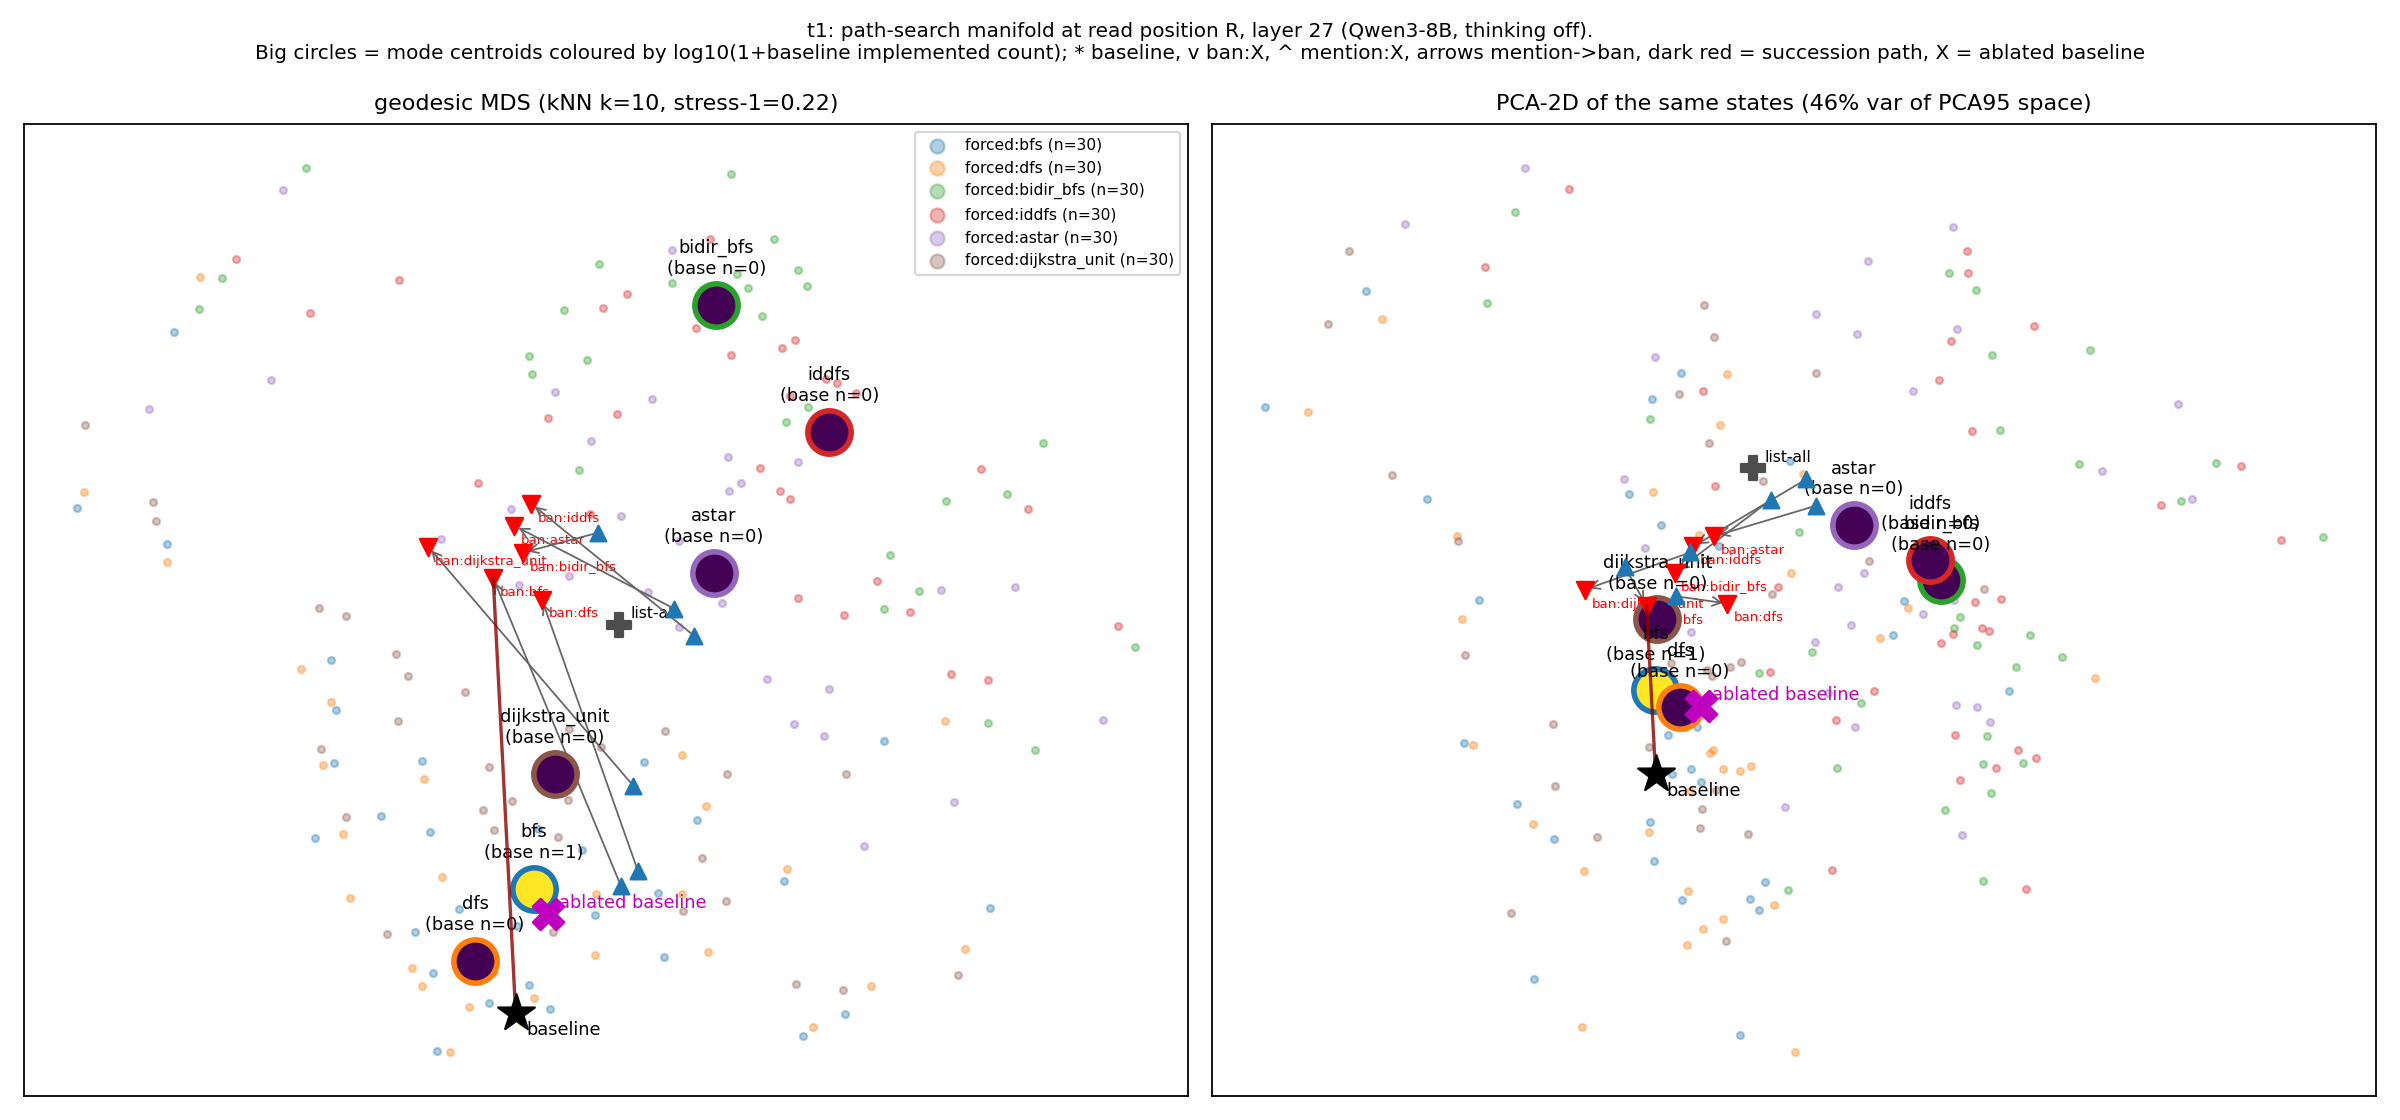

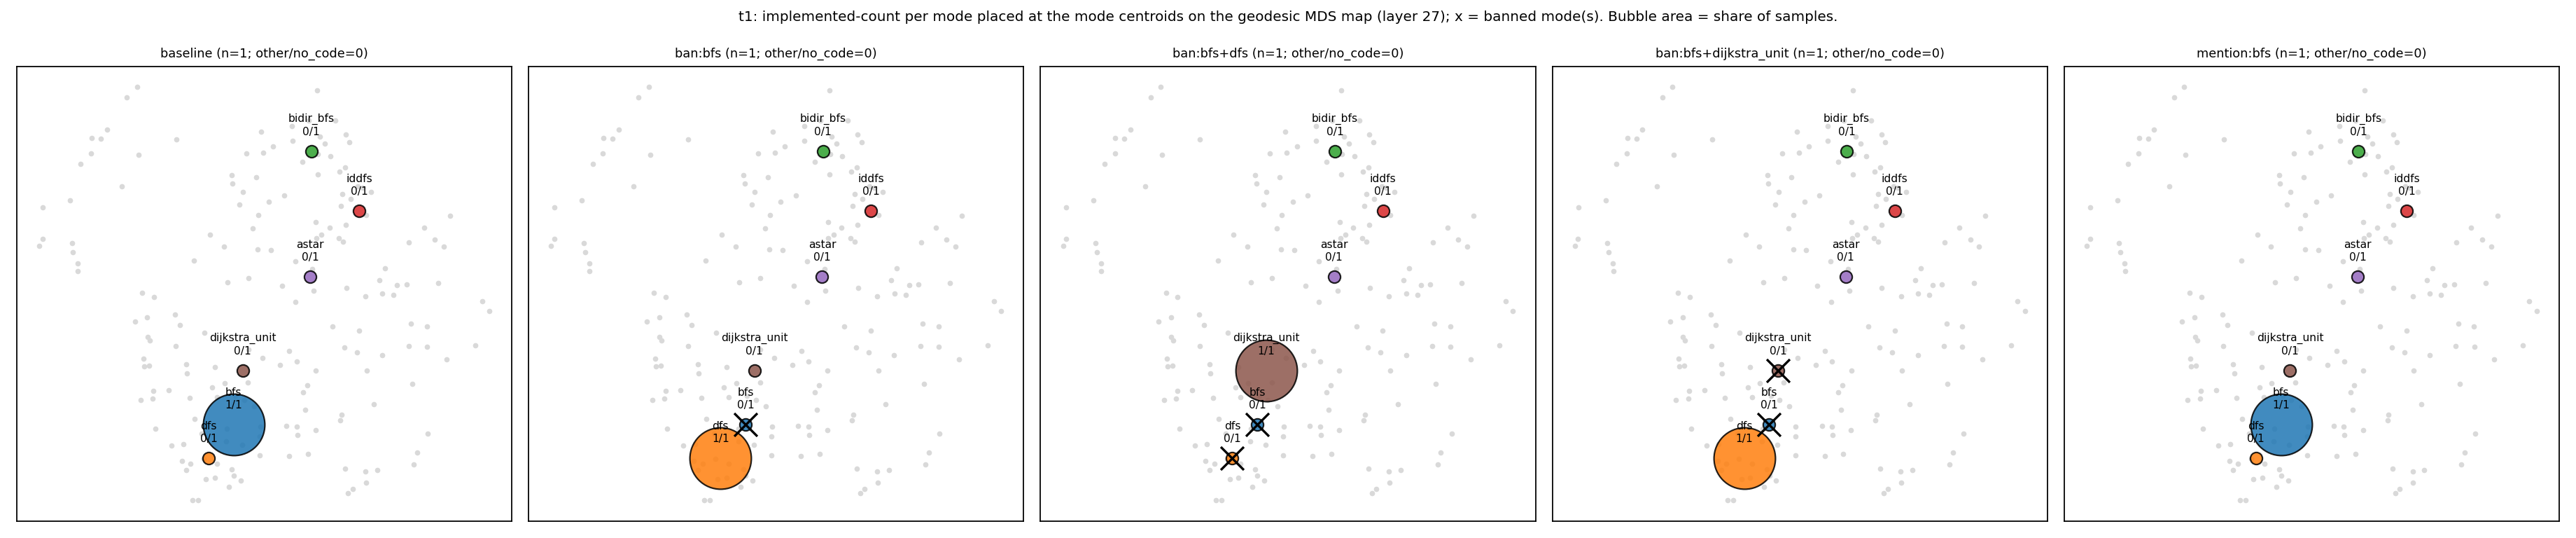

In [23]:
# ==== analysis/analyze.py: E4 manifold ====
def manifold(index, H, gate, summA, geoB, phaseC, rows=None) -> dict:
    import matplotlib.pyplot as plt
    from scipy.stats import spearmanr
    from sklearn.manifold import MDS

    out = {}
    for t in TASKS:
        cat = CATALOGUE[t]
        l = gate[t]["l_star"]
        iN = [i for i, r in enumerate(index) if r["task"] == t and r["condition"].startswith("forced:")]
        lab = [index[i]["condition"].split(":")[1] for i in iN]
        Xn = H[l][iN]
        mu, comps, ev = pca95(Xn)
        P = (Xn - mu) @ comps.T
        C = np.stack([Xn[[k for k, m in enumerate(lab) if m == mm]].mean(0) for mm in cat])
        G, ginfo = knn_graph(P, KNN_K)
        # leaf points: centroids, baseline, ban:X, mention:X, listall, succession, ablated baseline
        leaf_names, leaf_vecs = [], []
        for j, m in enumerate(cat):
            leaf_names.append(f"centroid:{m}")
            leaf_vecs.append(C[j])

        def mean_cond(c):
            ii = [i for i, r in enumerate(index) if r["task"] == t and r["condition"] == c]
            return H[l][ii].mean(0) if ii else None

        conds = ["baseline", "listall"] + [f"ban:{m}" for m in cat] + [f"mention:{m}" for m in cat]
        chain = phaseC.get("succession", {}).get(t, {}).get("chain", [])
        for k in range(2, len(chain) + 1):
            conds.append("ban:" + "+".join(chain[:k]))
        for c in conds:
            v = mean_cond(c)
            if v is not None:
                leaf_names.append(c)
                leaf_vecs.append(v)
        abl = data["hR_states"].get("ablated_baseline_mean")  # original: np.load(CACHE / f"hR_ablated_{t}.npz")
        if abl is not None:
            band = [int(x) for x in abl["band"]]
            if l in band:
                leaf_names.append("ablated_baseline")
                leaf_vecs.append(np.asarray(abl["coords"], dtype=np.float32))  # original: Z["h"][band.index(l)].mean(0)
        Q = (np.stack(leaf_vecs) - mu) @ comps.T
        GA = attach(G, P, Q, KNN_K)
        from scipy.sparse.csgraph import shortest_path

        Dall = shortest_path(GA, directed=False)
        Dall = (Dall + Dall.T) / 2
        finite = np.isfinite(Dall).all()
        mds = MDS(n_components=2, dissimilarity="precomputed", n_init=MDS_N_INIT, random_state=0, normalized_stress="auto")
        Y = mds.fit_transform(np.where(np.isfinite(Dall), Dall, np.nanmax(Dall[np.isfinite(Dall)]) * 2))
        from scipy.spatial.distance import pdist, squareform

        Dy = squareform(pdist(Y))
        iu = np.triu_indices(len(Dall), 1)
        stress1 = float(np.sqrt(np.sum((Dall[iu] - Dy[iu]) ** 2) / np.sum(Dall[iu] ** 2)))
        # geodesic vs euclidean rank correlation (over points)
        from scipy.spatial.distance import cdist

        De = cdist(P, P)
        npnt = len(P)
        ii = np.triu_indices(npnt, 1)
        rho = float(spearmanr(Dall[:npnt, :npnt][ii], De[ii])[0])
        # testing plan 8: geodesic >= Euclidean for every pair, symmetric distance matrix
        Graw = shortest_path(GA, directed=False)
        geo_checks = {"geodesic_ge_euclidean_all_pairs": bool((Dall[:npnt, :npnt] + 1e-4 >= De).all()),
                      "symmetric_max_abs_diff": float(np.nanmax(np.abs(Graw - Graw.T)[np.isfinite(Graw)]))}
        # intrinsic dimension vs column-shuffled nulls
        idim = twonn_id(P)
        nulls = []
        for s in range(N_TWONN_NULLS):
            Ps = P.copy()
            for c in range(Ps.shape[1]):
                Ps[:, c] = RNG.permutation(Ps[:, c])
            nulls.append(twonn_id(Ps))
        counts = {m: summA[t]["baseline_label_counts"].get(m, 0) for m in cat}
        out[t] = {"layer": l, "pca_dims": int(comps.shape[0]), "pca_explained": float(ev.sum()), "graph": ginfo,
                  "mds_stress1": stress1, "geodesic_vs_euclidean_spearman": rho, "twonn_id": idim,
                  "twonn_null_mean": float(np.nanmean(nulls)), "twonn_null_p5_p95": [float(np.nanpercentile(nulls, 5)),
                                                                                       float(np.nanpercentile(nulls, 95))],
                  "leaf_names": leaf_names, "mds_xy_leaves": Y[npnt:].tolist(), "all_finite": bool(finite),
                  "centroid_geodesic": Dall[npnt:npnt + len(cat), npnt:npnt + len(cat)].tolist(),
                  "baseline_counts": counts, "checks": geo_checks}
        # ---------------------------------------------------------------- figure: MDS + PCA side by side
        cmap = plt.get_cmap("tab10")
        fig, axes = plt.subplots(1, 2, figsize=(15, 7.0))
        Ppca = P[:, :2]
        Qpca = Q[:, :2]
        for ax, (pts, lv, title) in zip(axes, [(Y[:npnt], Y[npnt:], f"geodesic MDS (kNN k={KNN_K}, stress-1={stress1:.2f})"),
                                               (Ppca, Qpca, f"PCA-2D of the same states ({ev[:2].sum() * 100:.0f}% var of PCA95 space)")]):
            for j, m in enumerate(cat):
                sel = [k for k, mm in enumerate(lab) if mm == m]
                ax.scatter(pts[sel, 0], pts[sel, 1], s=10, alpha=0.35, color=cmap(j), label=f"forced:{m} (n={len(sel)})")
            vmax = max(np.log10(1 + max(counts.values())), 1e-6)
            for j, m in enumerate(cat):
                c = math.log10(1 + counts[m]) / vmax
                ax.scatter(lv[j, 0], lv[j, 1], s=380, marker="o", c=[plt.get_cmap("viridis")(c)], edgecolors=cmap(j),
                           linewidths=2.5, zorder=5)
                ax.annotate(f"{m}\n(base n={counts[m]})", lv[j], fontsize=8, ha="center", va="bottom",
                            xytext=(0, 12), textcoords="offset points", zorder=6)
            name_pos = {n: lv[k] for k, n in enumerate(leaf_names)}
            for n, p in name_pos.items():
                if n.startswith("centroid"):
                    continue
                if n == "baseline":
                    ax.scatter(*p, marker="*", s=300, c="k", zorder=7)
                    ax.annotate("baseline", p, fontsize=8, xytext=(5, -10), textcoords="offset points")
                elif n == "listall":
                    ax.scatter(*p, marker="P", s=120, c="0.3", zorder=7)
                    ax.annotate("list-all", p, fontsize=7, xytext=(5, 3), textcoords="offset points")
                elif n == "ablated_baseline":
                    ax.scatter(*p, marker="X", s=200, c="m", zorder=7)
                    ax.annotate("ablated baseline", p, fontsize=8, color="m", xytext=(5, 3), textcoords="offset points")
                elif n.startswith("ban:") and "+" not in n:
                    ax.scatter(*p, marker="v", s=60, c="r", zorder=6)
                    ax.annotate(n, p, fontsize=6, color="r", xytext=(3, -8), textcoords="offset points")
                elif n.startswith("ban:"):
                    ax.scatter(*p, marker="D", s=50, c="darkred", zorder=6)
                elif n.startswith("mention:"):
                    ax.scatter(*p, marker="^", s=50, c="tab:blue", zorder=6)
            for m in cat:
                a, b = name_pos.get(f"mention:{m}"), name_pos.get(f"ban:{m}")
                if a is not None and b is not None:
                    ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="->", color="0.4", lw=0.8))
            path = ["baseline"] + ["ban:" + "+".join(chain[:k]) for k in range(1, len(chain) + 1)]
            path = [name_pos[p] for p in path if p in name_pos]
            if len(path) >= 2:
                pa = np.array(path)
                ax.plot(pa[:, 0], pa[:, 1], "-", color="darkred", lw=1.5, alpha=0.8, zorder=6)
            ax.set_title(title, fontsize=10)
            ax.set_xticks([])
            ax.set_yticks([])
        axes[0].legend(fontsize=7, loc="best", markerscale=2)
        fig.suptitle(f"{t}: path-search manifold at read position R, layer {l} (Qwen3-8B, thinking off).\nBig circles = "
                     f"mode centroids coloured by log10(1+baseline implemented count); * baseline, v ban:X, ^ mention:X, "
                     f"arrows mention->ban, dark red = succession path, X = ablated baseline", fontsize=9)
        fig.tight_layout()
        for ext in ("png", "pdf"):
            fig.savefig(FIG / f"manifold_{t}.{ext}", dpi=160)
        plt.close(fig)
        # ---------------------------------------------------------------- figure: where do the bans send the model?
        if rows is not None:
            X1 = summA[t]["modal"]
            ban_conds = sorted({r["condition"] for r in rows["C"] if r["task"] == t and r["condition"].startswith("ban:")},
                               key=lambda c: (c.count("+"), c))
            panels = [("baseline", [r for r in rows["A"] if r["task"] == t and r["condition"] == "baseline"])]
            panels += [(c, [r for r in rows["C"] if r["task"] == t and r["condition"] == c]) for c in ban_conds]
            mcond = f"mention:{X1}"
            mr = [r for r in rows["C"] if r["task"] == t and r["condition"] == mcond]
            if mr:
                panels.append((mcond, mr))
            fig, axes = plt.subplots(1, len(panels), figsize=(4.6 * len(panels), 4.8), squeeze=False)
            for ax, (c, rr) in zip(axes[0], panels):
                cnt = Counter(r["label"] for r in rr)
                ax.scatter(Y[:npnt, 0], Y[:npnt, 1], s=6, c="0.85")
                for j, m in enumerate(cat):
                    k = cnt.get(m, 0)
                    ax.scatter(Y[npnt + j, 0], Y[npnt + j, 1], s=60 + 1500 * k / max(len(rr), 1), color=cmap(j),
                               alpha=0.85, edgecolors="k", zorder=5)
                    ax.annotate(f"{m}\n{k}/{len(rr)}", (Y[npnt + j, 0], Y[npnt + j, 1]), fontsize=7, ha="center",
                                va="bottom", xytext=(0, 9), textcoords="offset points", zorder=6)
                banned = c.split(":", 1)[1].split("+") if c.startswith("ban:") else []
                for b in banned:
                    jb = cat.index(b)
                    ax.scatter(Y[npnt + jb, 0], Y[npnt + jb, 1], marker="x", s=220, c="k", zorder=7)
                oth = cnt.get("other", 0) + cnt.get("no_code", 0)
                ax.set_title(f"{c} (n={len(rr)}; other/no_code={oth})", fontsize=8)
                ax.set_xticks([])
                ax.set_yticks([])
            fig.suptitle(f"{t}: implemented-count per mode placed at the mode centroids on the geodesic MDS map "
                         f"(layer {l}); x = banned mode(s). Bubble area = share of samples.", fontsize=9)
            fig.tight_layout()
            for ext in ("png", "pdf"):
                fig.savefig(FIG / f"ban_shift_on_manifold_{t}.{ext}", dpi=160)
            plt.close(fig)
    return out


t_stage = time.time()
phaseC = data["metadata"]["phaseC"]  # results/phaseC_events.json (succession chain + exploratory flags)
man = manifold(index, H, gate, summA, geo_out, phaseC, rows)
jdump(man, "manifold.json")
m, refm = man["t1"], data["metadata"]["full_run_reference"]["manifold_t1"]
print(f"manifold computed in {time.time() - t_stage:.1f}s")
print(f"PCA95 dims {m['pca_dims']} (full run {refm['pca_dims']}) | MDS stress-1 {m['mds_stress1']:.3f} ({refm['mds_stress1']:.3f}) | "
      f"geodesic-vs-Euclidean Spearman {m['geodesic_vs_euclidean_spearman']:.3f} ({refm['geodesic_vs_euclidean_spearman']:.3f})")
print(f"TwoNN intrinsic dimension {m['twonn_id']:.2f} vs column-shuffled nulls {m['twonn_null_mean']:.2f} "
      f"[p5 {m['twonn_null_p5_p95'][0]:.2f}, p95 {m['twonn_null_p5_p95'][1]:.2f}] "
      f"(full run {refm['twonn_id']:.2f} vs {refm['twonn_null_mean']:.2f})")
print(f"checks: {m['checks']} | max |centroid geodesic - full run| = "
      f"{np.abs(np.array(m['centroid_geodesic']) - np.array(refm['centroid_geodesic'])).max():.4f}")
display(Image(filename=str(FIG / "manifold_t1.png"), width=1100))
display(Image(filename=str(FIG / "ban_shift_on_manifold_t1.png"), width=1100))

### E5: the forecast contest

Each ban event is scored against the forecasts **committed before its samples existed**. The realised mode is the most common label among the *compliant* programs, and it must lead the runner-up by at least 15% of them. Every predictor gets a top-1 hit (`None` when its forecast is tied, as frequency is when the baseline is 100% BFS). It also gets a smoothed log score over the programs that landed on a survivor or `other`, the JS divergence to the realised distribution, and its top-2 agreement. `ban:bfs` is the primary event; the step-2 bans are exploratory.

The demo scores the replayed subset, so its counts are a few programs per event; the full-run counts are printed alongside. The full run also checked that every event's first sample was drawn after the commit timestamp. The replayed rows do not carry sampling timestamps, so that check is not repeated.

In [24]:
# ==== analysis/analyze.py: E5 contest ====
PREDS = ["association", "frequency", "geodesic", "decoder"]


def score_event(ev: dict, rr: list[dict], cat: list[str]) -> dict:
    S = ev["survivors"]
    bset = ev["banset"]
    comp = [r for r in rr if r["passed"] and r["label"] not in bset and r["label"] != "no_code"]
    cnt = Counter(r["label"] for r in comp)
    real = np.array([cnt.get(m, 0) for m in S], float)
    lead_ok = False
    ranked = cnt.most_common()
    if ranked:
        lead = (ranked[0][1] - (ranked[1][1] if len(ranked) > 1 else 0)) / max(len(comp), 1)
        lead_ok = lead >= 0.15
    realised = ranked[0][0] if (ranked and lead_ok) else None
    out = {"n": len(rr), "n_compliant": len(comp), "compliance": len(comp) / max(len(rr), 1),
           "realised_counts": dict(cnt), "realised_mode": realised or "no clear mode",
           "realised_in_survivors": realised in S if realised else None, "predictors": {}}
    scored = [r for r in rr if r["label"] in S or r["label"] == "other"]
    for p in PREDS + ["association_X1"]:
        q = np.array([ev["distributions"][p][m] for m in S])
        top1 = S[int(np.argmax(q))]
        qm = 0.98 * (0.95 * q + 0.05 / len(S))
        lp = [math.log(qm[S.index(r["label"])]) if r["label"] in S else math.log(0.02) for r in scored]
        rs = real + 0.5
        js = js_div(q, rs / rs.sum())
        from scipy.stats import spearmanr

        sp = float(spearmanr(q, real)[0]) if len(S) > 2 and real.std() > 0 and q.std() > 0 else float("nan")
        top2p = set(np.array(S)[np.argsort(-q)[:2]])
        top2r = set(np.array(S)[np.argsort(-real)[:2]])
        tied = bool(ev.get("top1_tied", {}).get(p, False))
        out["predictors"][p] = {"top1": top1, "tied": tied,
                                "hit": (None if tied else ((top1 == realised) if realised else False)),
                                "log_score_mean": float(np.mean(lp)) if lp else float("nan"), "n_scored": len(lp),
                                "js_to_realised": js, "spearman": sp, "top2_agreement": len(top2p & top2r) / 2}
    return out


def contest(rows, preds, phaseC) -> dict:
    events = {}
    for eid, ev in preds["events"].items():
        t = ev["task"]
        cat = CATALOGUE[t]
        if ev["kind"] == "ban":
            cond = "ban:" + "+".join(ev["banset"])
            rr = [r for r in rows["C"] if r["task"] == t and r["condition"] == cond]
        else:
            # removal event scored on the strongest successful d_X arm (filled in by c2)
            continue
        if not rr:
            continue
        sc = score_event(ev, rr, cat)
        per_para = {}
        for pid in sorted({r["paraphrase_id"] for r in rr}):
            rp = [r for r in rr if r["paraphrase_id"] == pid]
            per_para[pid] = {"n": len(rp), "compliant": sum(r["passed"] and r["label"] not in ev["banset"] and r["label"] != "no_code" for r in rp),
                             "labels": dict(Counter(r["label"] for r in rp))}
        sc["per_paraphrase"] = per_para
        sc["exploratory"] = bool(phaseC.get("events", {}).get(eid, {}).get("exploratory", False))
        sc["ban_failure"] = sc["compliance"] < 0.5
        sc.update({"event": eid, "task": t, "banset": ev["banset"], "survivors": ev["survivors"],
                   "committed_top1": ev["top1"], "concordance": ev["concordance"], "stability": ev["stability"],
                   "ambiguity_flag": ev["ambiguity_flag"]})
        events[eid] = sc
    return events


def contest_aggregate(events: dict, primary_only: bool = False) -> dict:
    agg = {}
    sc = [e for e in events.values() if not (primary_only and e.get("exploratory"))]
    for p in PREDS + ["association_X1"]:
        scored = [e for e in sc if e["predictors"][p]["hit"] is not None]
        hits = sum(bool(e["predictors"][p]["hit"]) for e in scored)
        n = len(scored)
        agg[p] = {"hits": hits, "events": n, "events_tied_excluded": len(sc) - n, "hit_rate": hits / max(n, 1),
                  "wilson": wilson(hits, n),
                  "mean_log_score": float(np.nanmean([e["predictors"][p]["log_score_mean"] for e in sc])) if sc else None,
                  "mean_js": float(np.nanmean([e["predictors"][p]["js_to_realised"] for e in sc])) if sc else None,
                  "mean_top2": float(np.nanmean([e["predictors"][p]["top2_agreement"] for e in sc])) if sc else None}
    trio = ["association", "frequency", "geodesic"]
    M = {a: {b: float(np.mean([e["committed_top1"][a] == e["committed_top1"][b] for e in sc])) if sc else None
             for b in trio} for a in trio}
    return {"per_predictor": agg, "agreement_matrix_top1": M, "n_events": len(sc),
            "note": "descriptive only: about 4-7 events, no p-values"}


preds = {"events": committed}
ce = contest(rows, preds, phaseC)
for eid, e in ce.items():  # (from analyze.main)
    e["commit_sha256"] = data["metadata"]["predictions"]["commit_sha256"]
    e["distributions"] = preds["events"][eid]["distributions"]
    e["hits"] = {p: e["predictors"][p]["hit"] for p in PREDS}
agg = contest_aggregate(ce)
agg_primary = contest_aggregate(ce, primary_only=True)
jdump({"events": ce, "aggregate_all": agg, "aggregate_primary": agg_primary}, "contest.json")

ref_c = data["metadata"]["full_run_reference"]["contest_events_t1"]
for eid, e in ce.items():
    f_ = ref_c[eid]
    print(f"{eid} ({'exploratory' if e['exploratory'] else 'primary'}): demo n={e['n']} compliance={e['compliance']:.2f} "
          f"compliant={e['realised_counts']} realised={e['realised_mode']} | full run n={f_['n']} "
          f"compliance={f_['compliance']:.2f} compliant={f_['realised_counts']} realised={f_['realised_mode']}")
    for p in PREDS:
        v = e["predictors"][p]
        print(f"    {p:<12} committed top1={v['top1']:<14} hit={str(v['hit']):<6} log score demo {v['log_score_mean']:7.2f}"
              f" | full run {f_['log_score_mean'][p]:7.2f}")
print("\nmean log score per predictor (all demo events):",
      {p: round(v["mean_log_score"], 2) for p, v in agg["per_predictor"].items() if p in PREDS})
print("mean log score per predictor (primary event only):",
      {p: round(v["mean_log_score"], 2) for p, v in agg_primary["per_predictor"].items() if p in PREDS})

t1|ban:bfs (primary): demo n=1 compliance=0.00 compliant={} realised=no clear mode | full run n=100 compliance=0.18 compliant={'dijkstra_unit': 8, 'dfs': 10} realised=no clear mode
    association  committed top1=astar          hit=False  log score demo   -4.24 | full run   -3.54
    frequency    committed top1=dfs            hit=None   log score demo   -1.63 | full run   -1.63
    geodesic     committed top1=dfs            hit=False  log score demo   -1.28 | full run   -1.34
    decoder      committed top1=dfs            hit=False  log score demo   -0.47 | full run   -1.29
t1|ban:bfs+dfs (exploratory): demo n=1 compliance=1.00 compliant={'dijkstra_unit': 1} realised=dijkstra_unit | full run n=50 compliance=0.36 compliant={'dijkstra_unit': 18} realised=dijkstra_unit
    association  committed top1=dijkstra_unit  hit=True   log score demo   -1.00 | full run   -1.00
    frequency    committed top1=bidir_bfs      hit=None   log score demo   -1.41 | full run   -1.41
    geodesic     commit

## Results

The tables and the figure below sum up what the demo re-derived. They answer three questions:
- Does the live pipeline reproduce the full run (labels, tests, geometry, committed forecasts)?
- Where does banning BFS send the model on the layer-27 manifold?
- Which forecast saw it coming?

**Left panel.** The four committed forecasts for `ban:bfs`, next to where the *compliant* programs actually went: in the full run (N = 100) and in this demo's replayed subset.

**Right panel.** Each mode's geodesic distance from the BFS centroid against the share of *all* `ban:bfs` programs that implemented it. The displaced mass lands on the nearest neighbours, DFS and unit-Dijkstra. The far modes, A*, IDDFS and bidirectional BFS, receive nothing.

REPRODUCTION CHECKS (live CPU stages vs the full run)
  [OK] hidden tests rebuilt from seed 1 are identical
  [OK] labeller unit tests: runtime and AST right on all 11 references + mutants
  [OK] PCA95 dims = 22
  [OK] centroid geodesics = full run (max diff < 0.01)
  [OK] geodesic forecasts = committed (max diff < 1e-3)
  [OK] association forecasts = committed (max diff < 1e-6)
  live labeller vs full run: same label 20/21, same pass/fail 21/21 (any difference is listed in section 7)

KEY NUMBERS (T1, Qwen3-8B)              demo subset            full run
  baseline BFS share                       1/1                    200/200
  ban:bfs                compliance            0.00 (n=1)             0.18 (n=100)
  ban:bfs+dfs            compliance            1.00 (n=1)             0.36 (n=50)
  ban:bfs+dijkstra_unit  compliance            0.00 (n=1)             0.10 (n=50)
  mention:bfs            compliance            1.00 (n=1)             1.00 (n=50)
  TwoNN intrinsic dim (vs shuffled

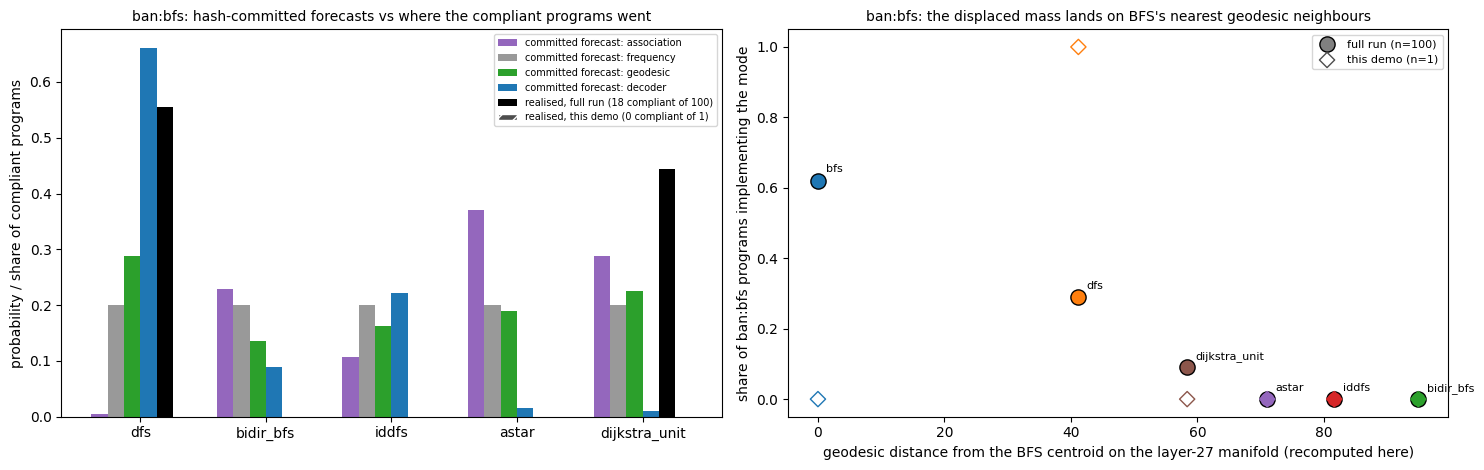

In [25]:
cat = CATALOGUE["t1"]
ref = data["metadata"]["full_run_reference"]
print("=" * 100)
print("REPRODUCTION CHECKS (live CPU stages vs the full run)")
print("=" * 100)
unit_res = json.loads((ROOT / "labeller" / "unit_test_results.json").read_text())
checks = [
    ("hidden tests rebuilt from seed 1 are identical", sha256_text(json.dumps(load_tests("t1")["tests"])) == ref_ht["tests_sha256"]),
    (f"labeller unit tests: runtime and AST right on all {len(unit_res)} references + mutants",
     all(r["runtime"] == r["expect"] and r["ast"] == r["expect"] for r in unit_res)),
    (f"PCA95 dims = {refm['pca_dims']}", man["t1"]["pca_dims"] == refm["pca_dims"]),
    ("centroid geodesics = full run (max diff < 0.01)",
     np.abs(np.array(man["t1"]["centroid_geodesic"]) - np.array(refm["centroid_geodesic"])).max() < 0.01),
    ("geodesic forecasts = committed (max diff < 1e-3)",
     max(abs(ev["distributions"]["geodesic"][m_] - committed[e_]["distributions"]["geodesic"][m_])
         for e_, ev in preds_live["events"].items() for m_ in ev["survivors"]) < 1e-3),
    ("association forecasts = committed (max diff < 1e-6)",
     max(abs(ev["distributions"]["association"][m_] - committed[e_]["distributions"]["association"][m_])
         for e_, ev in preds_live["events"].items() for m_ in ev["survivors"]) < 1e-6),
]
for name, ok in checks:
    print(f"  [{'OK' if ok else '--'}] {name}")
print(f"  live labeller vs full run: same label {same_label}/{len(allrows)}, same pass/fail {same_pass}/{len(allrows)} "
      f"(any difference is listed in section 7)")

print("\nKEY NUMBERS (T1, Qwen3-8B)              demo subset            full run")
b_demo, b_full = summ["t1"]["baseline"], ref["summaries_t1"]["baseline"]
print(f"  baseline BFS share                       {b_demo['label_counts'].get('bfs', 0)}/{b_demo['n']:<20} {b_full['label_counts'].get('bfs', 0)}/{b_full['n']}")
for c in ("ban:bfs", "ban:bfs+dfs", "ban:bfs+dijkstra_unit", "mention:bfs"):
    if c in summ["t1"]:
        d_, f_ = summ["t1"][c], ref["summaries_t1"][c]
        print(f"  {c:<22} compliance            {d_['compliance']:.2f} (n={d_['n']}){'':<12} {f_['compliance']:.2f} (n={f_['n']})")
print(f"  TwoNN intrinsic dim (vs shuffled null)   {man['t1']['twonn_id']:.2f} ({man['t1']['twonn_null_mean']:.2f}){'':<12} "
      f"{refm['twonn_id']:.2f} ({refm['twonn_null_mean']:.2f})")
print(f"  geodesic BFS -> DFS / unit-Dijkstra      {man['t1']['centroid_geodesic'][0][1]:.0f} / {man['t1']['centroid_geodesic'][0][5]:.0f}"
      f"{'':<17} {refm['centroid_geodesic'][0][1]:.0f} / {refm['centroid_geodesic'][0][5]:.0f}")
print(f"  geodesic BFS -> A* / IDDFS / bidir BFS   {man['t1']['centroid_geodesic'][0][4]:.0f} / {man['t1']['centroid_geodesic'][0][3]:.0f} / "
      f"{man['t1']['centroid_geodesic'][0][2]:.0f}{'':<12} {refm['centroid_geodesic'][0][4]:.0f} / {refm['centroid_geodesic'][0][3]:.0f} / {refm['centroid_geodesic'][0][2]:.0f}")

# ---- figure: where does ban:bfs send the model, and which forecast saw it coming?
eid = "t1|ban:bfs"
S = committed[eid]["survivors"]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
x = np.arange(len(S))
w = 0.13
cols = {"association": "#9467bd", "frequency": "0.6", "geodesic": "#2ca02c", "decoder": "#1f77b4"}
for k, p in enumerate(PREDS):
    axes[0].bar(x + (k - 2.5) * w, [committed[eid]["distributions"][p][m_] for m_ in S], w, color=cols[p],
                label=f"committed forecast: {p}")
full_c = np.array([ref["contest_events_t1"][eid]["realised_counts"].get(m_, 0) for m_ in S], float)
demo_c = np.array([ce[eid]["realised_counts"].get(m_, 0) for m_ in S], float) if eid in ce else np.zeros(len(S))
axes[0].bar(x + 1.5 * w, full_c / max(full_c.sum(), 1), w, color="k", label=f"realised, full run ({int(full_c.sum())} compliant of 100)")
axes[0].bar(x + 2.5 * w, demo_c / max(demo_c.sum(), 1), w, color="0.3", hatch="//", edgecolor="w",
            label=f"realised, this demo ({int(demo_c.sum())} compliant of {ce[eid]['n'] if eid in ce else 0})")
axes[0].set_xticks(x)
axes[0].set_xticklabels(S)
axes[0].set_ylabel("probability / share of compliant programs")
axes[0].set_title("ban:bfs: hash-committed forecasts vs where the compliant programs went", fontsize=10)
axes[0].legend(fontsize=7)
D_bfs = np.array(geo_out["t1"]["centroid_geodesic"][cat.index("bfs")])
full_all = ref["summaries_t1"]["ban:bfs"]["label_counts"]
demo_all = summ["t1"]["ban:bfs"]["label_counts"] if "ban:bfs" in summ["t1"] else {}
n_full, n_demo = ref["summaries_t1"]["ban:bfs"]["n"], max(sum(demo_all.values()), 1)
for j, m_ in enumerate(cat):
    axes[1].scatter(D_bfs[j], full_all.get(m_, 0) / n_full, s=120, color=plt.get_cmap("tab10")(j), edgecolors="k", zorder=5)
    axes[1].scatter(D_bfs[j], demo_all.get(m_, 0) / n_demo, s=60, marker="D", facecolors="none",
                    edgecolors=plt.get_cmap("tab10")(j), zorder=6)
    axes[1].annotate(m_, (D_bfs[j], full_all.get(m_, 0) / n_full), xytext=(6, 6), textcoords="offset points", fontsize=8)
axes[1].scatter([], [], s=120, color="0.5", edgecolors="k", label=f"full run (n={n_full})")
axes[1].scatter([], [], s=60, marker="D", facecolors="none", edgecolors="0.3", label=f"this demo (n={sum(demo_all.values())})")
axes[1].set_xlabel("geodesic distance from the BFS centroid on the layer-27 manifold (recomputed here)")
axes[1].set_ylabel("share of ban:bfs programs implementing the mode")
axes[1].set_title("ban:bfs: the displaced mass lands on BFS's nearest geodesic neighbours", fontsize=10)
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()